# Panda Lorenz–96: Tests A and B
Compare fine-tuned Panda models with the original checkpoint in six evaluation cases. Each forecast takes **512 slow-state observations** and directly predicts the next **128 observations**.

| Model | Test inputs and targets |
|---|---|
| Multiscale-fine-tuned Panda | Downsampled multiscale slow states |
| Single-scale-fine-tuned Panda | Single-scale states |
| Multiscale-fine-tuned Panda, cross-family | Single-scale states |
| Single-scale-fine-tuned Panda, cross-family | Downsampled multiscale slow states |
| Original Panda, zero-shot | Downsampled multiscale slow states |
| Original Panda, zero-shot | Single-scale states |

No fast states are loaded or predicted. Fine-tuned and zero-shot predictions within a family use identical contexts, targets, and forecast origins. The two data families have different targets and physical sampling intervals. Every case has its own figure. Section 9 evaluates all five Test B configurations without retraining.


## 1. Setup
Use the `panda` environment defined in `environments/panda.yml`. The notebook can run from the repository root or from `notebooks/`. CUDA, Apple MPS, and CPU are supported; device selection is automatic.

Restore the exported validation-selected weights **and** their saved polynomial feature indices. Inference uses float32 without autocast. These checkpoints have deterministic prediction heads, so we use their direct point predictions rather than sample a predictive distribution. Internal context scaling is handled by Panda, as in training.

The zero-shot baseline loads the locally cached original `GilpinLab/panda` checkpoint at the same pinned revision used to initialize fine-tuning. Upstream checkpoints omit polynomial feature indices; seed 99 initializes these indices, matching the fine-tuning initialization. Fine-tuned models restore their exported indices. No fine-tuned weights are used by the zero-shot baseline.


In [1]:
import gc
import json
from importlib.metadata import version
from pathlib import Path
import sys
from time import perf_counter

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src").is_dir() and (path / "data").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

from src.evaluation import relative_l2_error
from src.models.baseline.panda import build_panda_model, restore_panda_model

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Device: {device}; inference dtype: float32")
print({name: version(name) for name in ("panda", "torch", "transformers", "numpy")})


Device: cpu; inference dtype: float32
{'panda': '0.1.0', 'torch': '2.13.0', 'transformers': '4.40.2', 'numpy': '1.26.4'}


## 2. Evaluation protocol
Test A contains **16 independent trajectories per family**, each with 8,192 slow observations. Following the direct-forecast experiment in `panda_pilot.ipynb`, select **six distinct forecast origins per trajectory**, uniformly without replacement using a fixed seed. This gives **96 forecasts per case**. Windows can overlap; independent trajectories, rather than windows, are the aggregation units.

The same index origins are used for corresponding trajectory IDs in both families. Their physical times are not aligned: each family uses its own calibrated sampling interval. Comparisons use forecast lead in samples. Origins are selected before inference and are never selected using errors.

The original and fine-tuned models are evaluated on exactly the same windows within each data family. Test A therefore contains 576 forecasts across the six cases.

Cross-family forecasts reuse the exact target-family observations, targets, and origins. Only the checkpoint changes. Compare the two fine-tuned models within a fixed test family to assess transfer.


In [2]:
context_length = 512
prediction_length = 128
num_trajectories = 16
windows_per_trajectory = 6
window_seed = 99
batch_size = 6

data_root = project_root / "data" / "lorenz96_benchmark" / "test"
training_root = project_root / "outputs" / "panda_lorenz96" / "training"
families = {
    "multiscale": {
        "label": "Multiscale slow",
        "color": "tab:orange",
        "data_dir": data_root / "multiscale" / "a" / "slow_downsampled",
        "model_dir": training_root / "multiscale_seed99" / "model",
    },
    "singlescale": {
        "label": "Single-scale",
        "color": "tab:blue",
        "data_dir": data_root / "singlescale" / "a",
        "model_dir": training_root / "singlescale_seed99" / "model",
    },
}

zero_shot_checkpoint = "GilpinLab/panda"
zero_shot_revision = "0ede89c96f555749781978c5dea7f62e813a5ff6"
zero_shot_seed = 99

evaluation_cases = {}
for model_kind, model_label in (("finetuned", "Fine-tuned"), ("zeroshot", "Zero-shot")):
    for family, spec in families.items():
        evaluation_cases[f"{family}_{model_kind}"] = {
            "family": family,
            "model_kind": model_kind,
            "model_label": model_label,
            "label": f"{spec['label']} — {model_label.lower()}",
            "color": spec["color"],
            "model_dir": spec["model_dir"] if model_kind == "finetuned" else None,
        }

trajectory_ids = [f"trajectory_{index:03d}" for index in range(1, num_trajectories + 1)]
test_data = {}
for family, spec in families.items():
    paths = sorted(spec["data_dir"].glob("trajectory_*.npz"))
    if [path.stem for path in paths] != trajectory_ids:
        raise ValueError(f"Expected all 16 Test A trajectories in {spec['data_dir']}")
    for filename in ("model.safetensors", "config.json", "polynomial_indices.json"):
        if not (spec["model_dir"] / filename).is_file():
            raise FileNotFoundError(spec["model_dir"] / filename)

    trajectories = []
    for path in paths:
        # Read only the slow-state array, even if the source also contains fast states
        with np.load(path, allow_pickle=False) as archive:
            time = archive["time"].copy()
            state = archive["slow_states"].T.copy()
        if time.shape != (8192,) or state.shape != (8192, 9):
            raise ValueError(f"Unexpected Test A shape in {path}: {time.shape}, {state.shape}")
        if not np.isfinite(time).all() or not np.isfinite(state).all():
            raise ValueError(f"Nonfinite Test A values in {path}")
        intervals = np.diff(time)
        if not np.all(intervals > 0) or not np.allclose(intervals, intervals[0], rtol=1e-7, atol=0):
            raise ValueError(f"Expected a uniform increasing time grid in {path}")
        trajectories.append({"id": path.stem, "path": path, "time": time, "state": state})
    test_data[family] = trajectories

origins_by_trajectory = {}
for index, trajectory_id in enumerate(trajectory_ids):
    valid_origins = np.arange(context_length, 8192 - prediction_length + 1)
    rng = np.random.default_rng(np.random.SeedSequence([window_seed, index]))
    origins_by_trajectory[trajectory_id] = np.sort(
        rng.choice(valid_origins, size=windows_per_trajectory, replace=False)
    )

protocol_rows = []
for family, spec in families.items():
    time = test_data[family][0]["time"]
    sample_dt = float(time[1] - time[0])
    protocol_rows.append({
        "Family": spec["label"],
        "Trajectories": len(test_data[family]),
        "Forecasts": num_trajectories * windows_per_trajectory,
        "Channels": 9,
        "Sample interval": sample_dt,
        "Last forecast lead (physical time)": prediction_length * sample_dt,
    })
display(pd.DataFrame(protocol_rows).set_index("Family"))
display(pd.DataFrame(origins_by_trajectory).T.rename_axis("Trajectory").rename(
    columns=lambda index: f"Window {index + 1} origin"
))


,Trajectories,Forecasts,Channels,Sample interval,Last forecast lead (physical time)
Family,,,,,
Multiscale slow,16,96,9,0.014013,1.793722
Single-scale,16,96,9,0.013470,1.724138


,Window 1 origin,Window 2 origin,Window 3 origin,Window 4 origin,Window 5 origin,Window 6 origin
Trajectory,,,,,,
trajectory_001,1854,4332,4378,4779,6232,7744
trajectory_002,4023,4448,5320,5866,6575,6576
trajectory_003,1473,2405,3039,3481,5631,7690
trajectory_004,1017,1560,4918,6482,7272,7663
trajectory_005,1137,1840,2026,4205,6334,6830
trajectory_006,1424,3217,3886,5624,6237,6851
trajectory_007,774,3501,3740,4255,5663,6941
trajectory_008,3603,4001,4022,4880,7030,8056
trajectory_009,2456,3079,3799,3914,5345,5732


In [3]:
# Register the two checkpoint-to-test-family transfers before running inference
for case_spec in evaluation_cases.values():
    case_spec["training_family"] = case_spec["family"] if case_spec["model_kind"] == "finetuned" else None

cross_case_keys = []
for training_family, test_family in (("multiscale", "singlescale"), ("singlescale", "multiscale")):
    case = f"{training_family}_to_{test_family}"
    cross_case_keys.append(case)
    evaluation_cases[case] = {
        "family": test_family,
        "training_family": training_family,
        "model_kind": "finetuned",
        "model_label": f"Fine-tuned on {families[training_family]['label'].lower()}",
        "label": f"{families[test_family]['label']} — trained on {families[training_family]['label'].lower()}",
        "color": families[test_family]["color"],
        "model_dir": families[training_family]["model_dir"],
    }

display(pd.DataFrame([
    {
        "Case": evaluation_cases[case]["label"],
        "Training family": families[evaluation_cases[case]["training_family"]]["label"],
        "Test family": families[evaluation_cases[case]["family"]]["label"],
        "Checkpoint": str(evaluation_cases[case]["model_dir"].relative_to(project_root)),
    }
    for case in cross_case_keys
]).set_index("Case"))


,Training family,Test family,Checkpoint
Case,,,
Single-scale — trained on multiscale slow,Multiscale slow,Single-scale,outputs/panda_lorenz96/training/multiscale_see...
Multiscale slow — trained on single-scale,Single-scale,Multiscale slow,outputs/panda_lorenz96/training/singlescale_se...


## 3. Direct 512 → 128 inference
Each input has shape `[batch, 512, 9]`; each prediction has shape `[batch, 128, 9]`. Future observations are used only as evaluation targets and are never passed to the model. Load one model at a time to limit memory use. Rerunning this cell recomputes all forecasts.

Six separate cases are evaluated: the four original cases and the two cross-family fine-tuned checkpoints. The inference loop below includes the cross-family cases registered in the preceding code cell.


In [4]:
def load_evaluation_model(spec):
    if spec["model_kind"] == "finetuned":
        model = restore_panda_model(
            checkpoint=spec["model_dir"],
            polynomial_indices_path=spec["model_dir"] / "polynomial_indices.json",
            local_files_only=True,
        )
    else:
        model = build_panda_model(
            checkpoint=zero_shot_checkpoint, revision=zero_shot_revision,
            seed=zero_shot_seed, local_files_only=True,
        )
    if (model.config.context_length, model.config.prediction_length) != (context_length, prediction_length):
        raise ValueError(f"Checkpoint forecast lengths do not match the protocol: {spec['label']}")
    if model.config.distribution_output is not None:
        raise ValueError("This notebook expects a deterministic prediction head")
    return model.float().to(device).eval()


results = {}
inference_rows = []
for case, spec in evaluation_cases.items():
    model = load_evaluation_model(spec)

    start = perf_counter()
    case_results = []
    for trajectory in tqdm(test_data[spec["family"]], desc=spec["label"], unit="trajectory"):
        origins = origins_by_trajectory[trajectory["id"]]
        contexts = np.stack([
            trajectory["state"][origin - context_length:origin] for origin in origins
        ]).astype(np.float32)
        targets = np.stack([
            trajectory["state"][origin:origin + prediction_length] for origin in origins
        ])
        batches = []
        with torch.inference_mode():
            for first in range(0, windows_per_trajectory, batch_size):
                past = torch.from_numpy(contexts[first:first + batch_size]).to(device)
                predictions = model(
                    past_values=past,
                    past_observed_mask=torch.ones_like(past, dtype=torch.bool),
                    return_dict=True,
                ).prediction_outputs
                batches.append(predictions.cpu().numpy())
        predictions = np.concatenate(batches)
        if predictions.shape != targets.shape or not np.isfinite(predictions).all():
            raise ValueError(f"Invalid predictions for {case}/{trajectory['id']}")
        case_results.append({
            "trajectory_id": trajectory["id"],
            "origins": origins.copy(),
            "contexts": contexts,
            "targets": targets,
            "predictions": predictions,
        })
    results[case] = case_results
    inference_rows.append({
        "Case": spec["label"],
        "Forecasts": num_trajectories * windows_per_trajectory,
        "Inference seconds": perf_counter() - start,
        "Checkpoint": str(spec["model_dir"].relative_to(project_root)) if spec["model_dir"] else zero_shot_checkpoint,
    })
    del model, past, predictions
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()

display(pd.DataFrame(inference_rows).set_index("Case"))


,Forecasts,Inference seconds,Checkpoint
Case,,,
Multiscale slow — fine-tuned,96,2.292668,outputs/panda_lorenz96/training/multiscale_see...
Single-scale — fine-tuned,96,2.206225,outputs/panda_lorenz96/training/singlescale_se...
Multiscale slow — zero-shot,96,2.287667,GilpinLab/panda
Single-scale — zero-shot,96,2.916288,GilpinLab/panda
Single-scale — trained on multiscale slow,96,2.337629,outputs/panda_lorenz96/training/multiscale_see...
Multiscale slow — trained on single-scale,96,2.233812,outputs/panda_lorenz96/training/singlescale_se...


Single-scale — fine-tuned: 100%|##########| 16/16 [00:02<00:00,  7.25trajectory/s]
/opt/homebrew/Caskroom/miniconda/base/envs/panda/lib/python3.11/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Multiscale slow — trained on single-scale: 100%|##########| 16/16 [00:02<00:00,  7.16trajectory/s]


## 4. Relative L2 errors
At forecast lead $h$, compare all nine variables:
$$
e_{\mathrm{rel}}(h)=\frac{\|\widehat{x}_h-x_h\|_2}{\|x_h\|_2}.
$$
The whole-window relative L2 error combines all $128\times9$ entries in both norms. This differs from averaging the per-lead relative errors.

Both metrics call `src.evaluation.relative_l2_error`, which computes errors in float64. Average the six windows within each trajectory first, then report the mean and sample standard deviation across the 16 trajectories. Standard deviations describe trajectory variation, not confidence intervals.


In [5]:
trajectory_rows = []
error_curves = {}
for case, spec in evaluation_cases.items():
    relative_curves = []
    for result in results[case]:
        target = result["targets"]
        prediction = result["predictions"]
        relative_by_lead = relative_l2_error(target, prediction, axis=-1)
        window_relative_l2 = relative_l2_error(target, prediction, axis=(1, 2))
        if not np.isfinite(relative_by_lead).all() or not np.isfinite(window_relative_l2).all():
            raise ValueError("Relative L2 requires nonzero target norms for this summary")

        relative_curves.append(relative_by_lead.mean(axis=0))
        trajectory_rows.append({
            "Case": spec["label"],
            "Trajectory": result["trajectory_id"],
            "Window relative L2": window_relative_l2.mean(),
            "Mean lead relative L2": relative_by_lead.mean(),
            "Lead 128 relative L2": relative_by_lead[:, -1].mean(),
        })
    error_curves[case] = np.stack(relative_curves)

trajectory_metrics = pd.DataFrame(trajectory_rows)
metric_columns = ["Window relative L2", "Mean lead relative L2", "Lead 128 relative L2"]
summary = trajectory_metrics.groupby("Case", sort=False)[metric_columns].agg(["mean", "std"])
display(summary.round(4))
print("Each mean and standard deviation uses 16 trajectory-level values, each averaging six windows.")


Each mean and standard deviation uses 16 trajectory-level values, each averaging six windows.


Window relative L2  ... Lead 128 relative L2
                                                        mean  ...                  std
Case                                                          ...                     
Multiscale slow — fine-tuned                          0.4516  ...               0.0664
Single-scale — fine-tuned                             0.4579  ...               0.1155
Multiscale slow — zero-shot                           0.9082  ...               0.1160
Single-scale — zero-shot                              0.9263  ...               0.0958
Single-scale — trained on multiscale slow             0.4731  ...               0.0970
Multiscale slow — trained on single-scale             0.4777  ...               0.0697

[6 rows x 6 columns]

## 5. Relative L2 error versus forecast lead
Each of the six model–data cases has its own figure. The solid curve shows the median of the 16 trajectory-level mean-window curves. Shading shows their 25th–75th percentile range. All nine slow variables contribute to each error. Forecast lead is measured in samples, with each family retaining its own physical sampling interval.


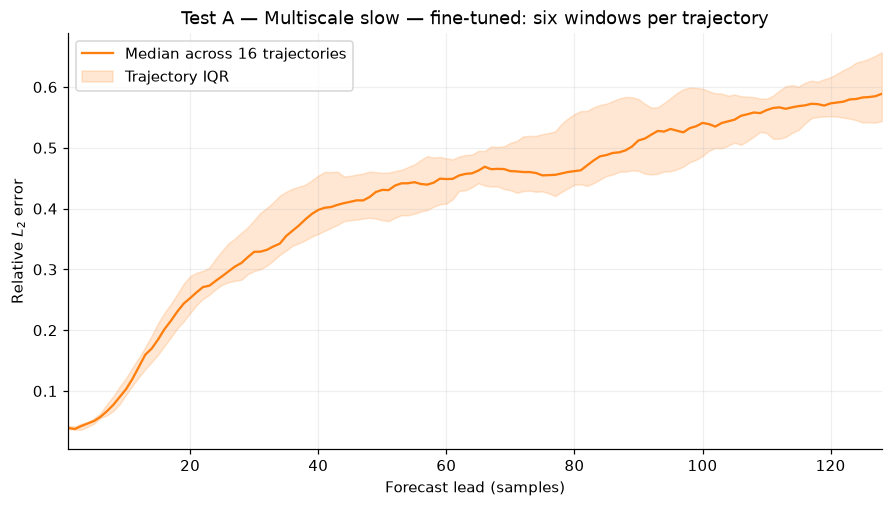

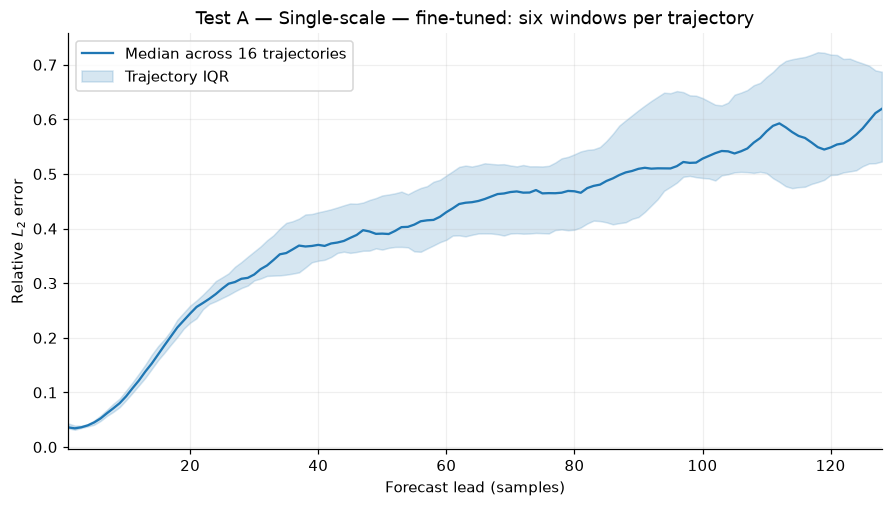

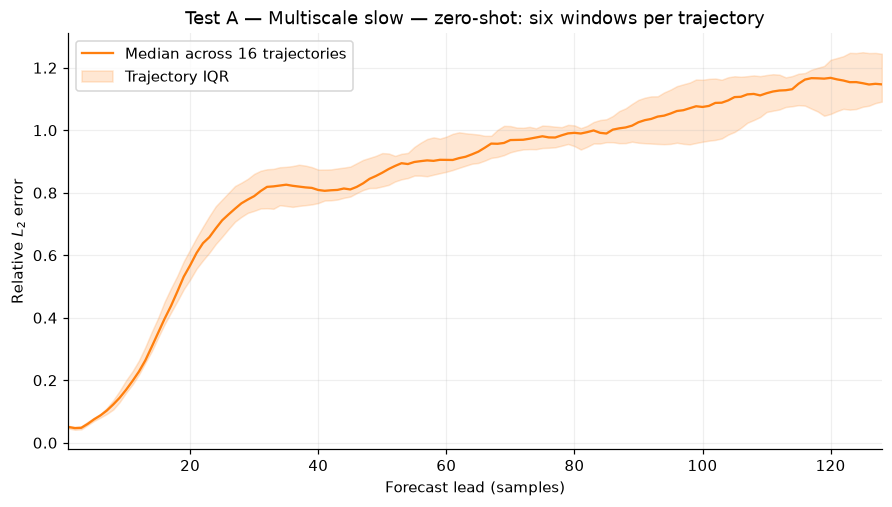

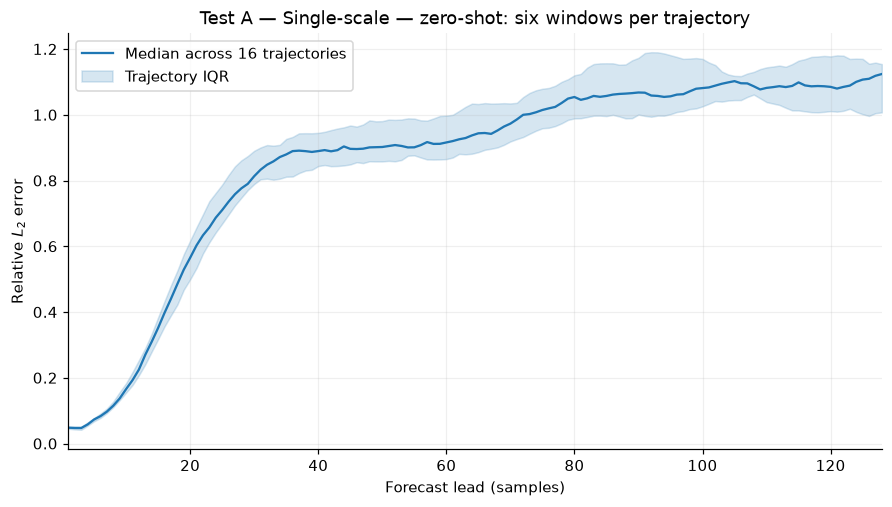

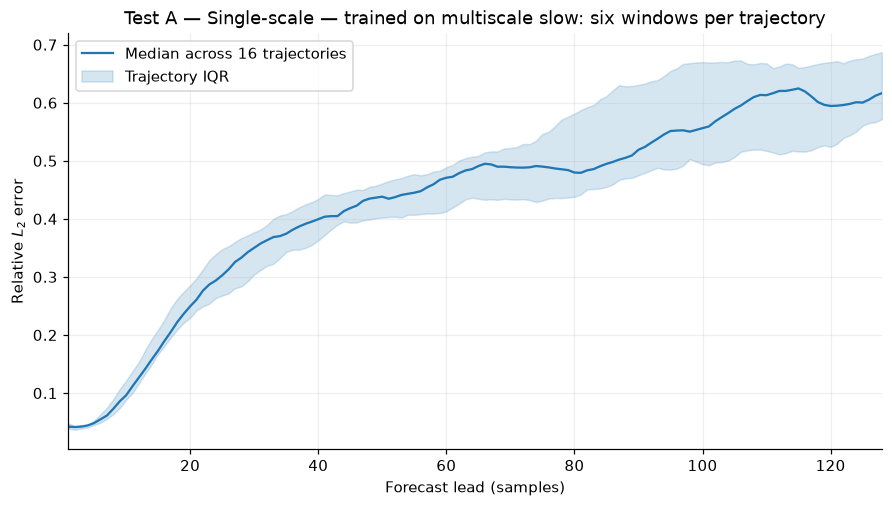

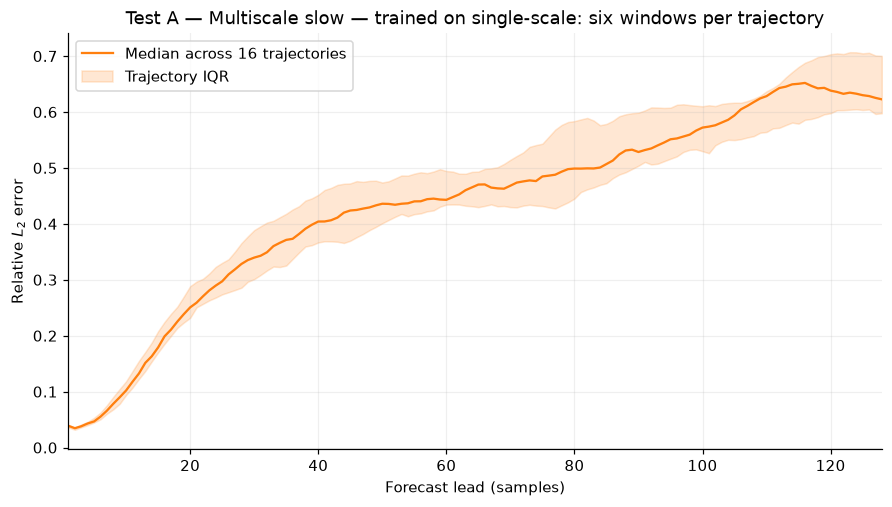

In [6]:
lead_times = np.arange(1, prediction_length + 1)
for case, spec in evaluation_cases.items():
    fig, axis = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    q25, median, q75 = np.quantile(error_curves[case], [0.25, 0.5, 0.75], axis=0)
    axis.plot(lead_times, median, color=spec["color"], label="Median across 16 trajectories")
    axis.fill_between(lead_times, q25, q75, color=spec["color"], alpha=0.18, label="Trajectory IQR")
    axis.set(
        xlabel="Forecast lead (samples)", ylabel=r"Relative $L_2$ error",
        xlim=(1, prediction_length), title=f"Test A — {spec['label']}: six windows per trajectory",
    )
    axis.grid(alpha=0.2)
    axis.legend()
    plt.show()


## 6. Representative forecasts
Use trajectory 001 and its first selected window, fixed independently of the results. Plot channels 0, 3, and 6 for readability; all nine channels were input, predicted, and scored. The full 512-point context is shown. Lead 0 is the last observed point and lead 1 is the first forecast point.

Within-family, cross-family, and zero-shot examples use the same trajectory and window, shown in separate figures.


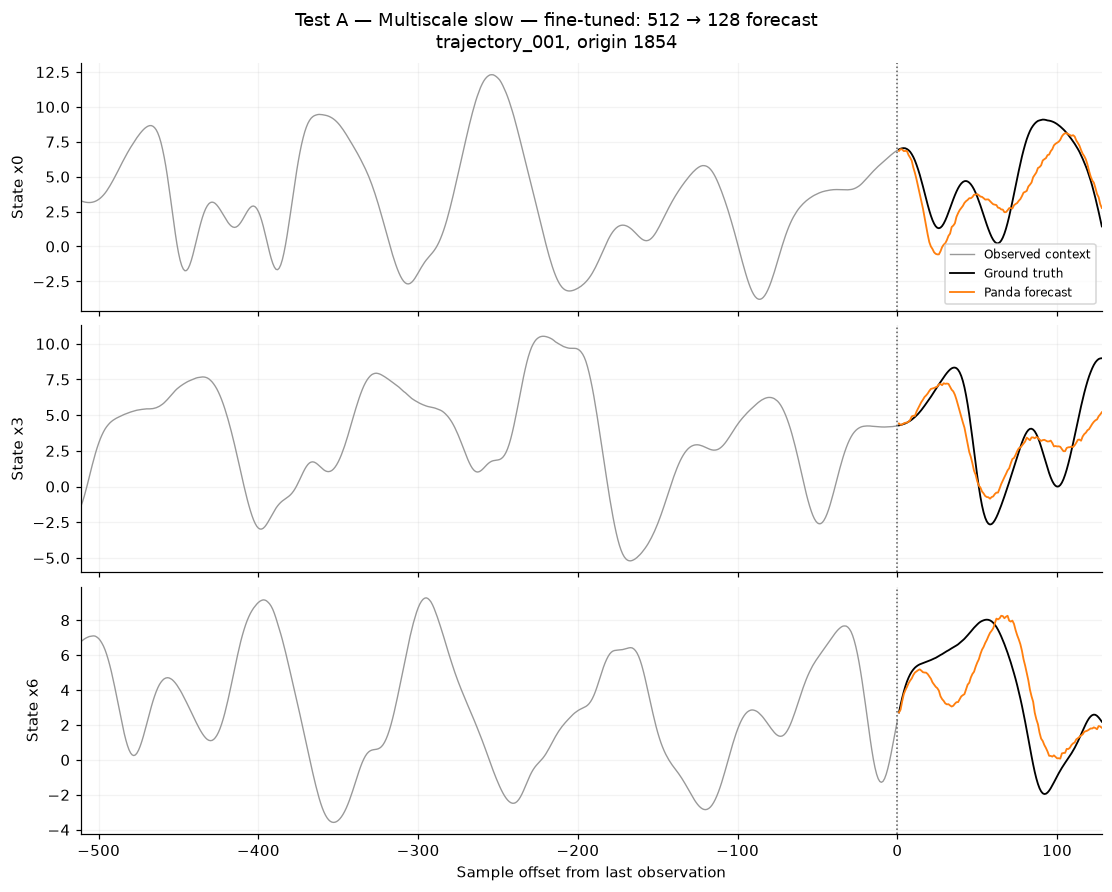

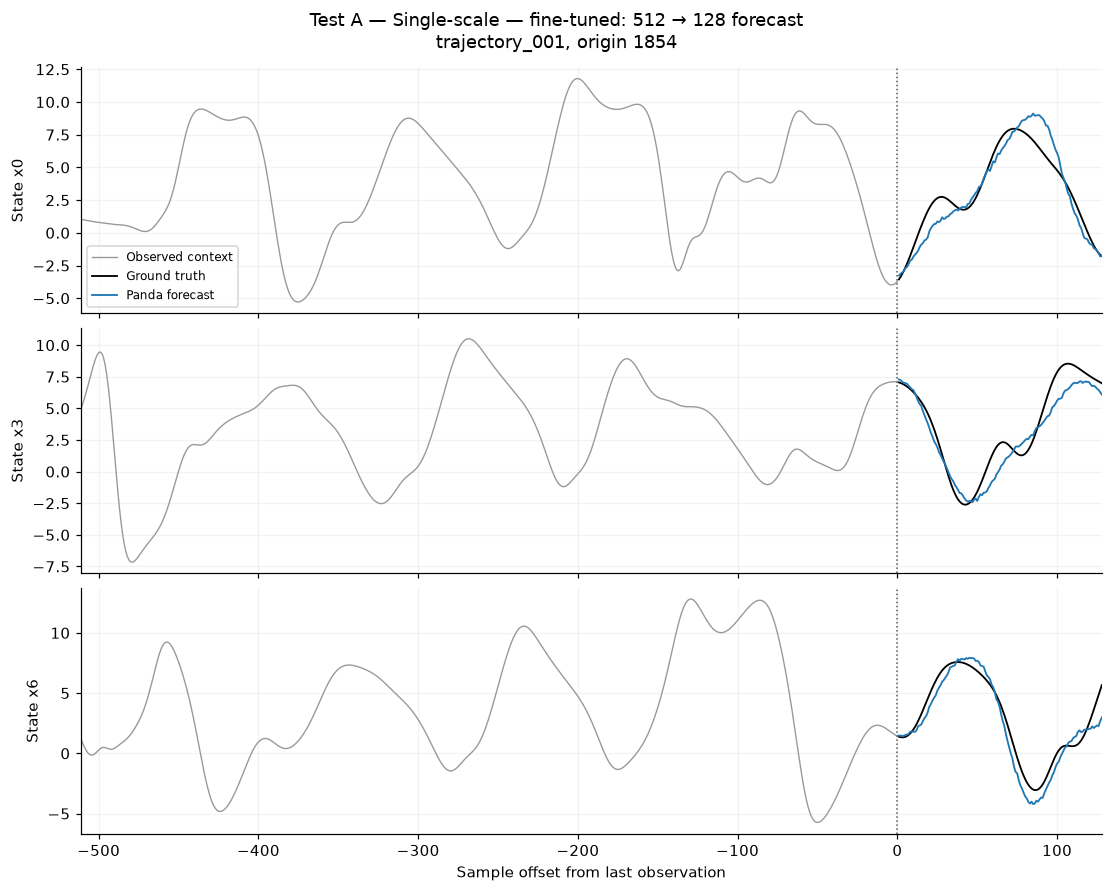

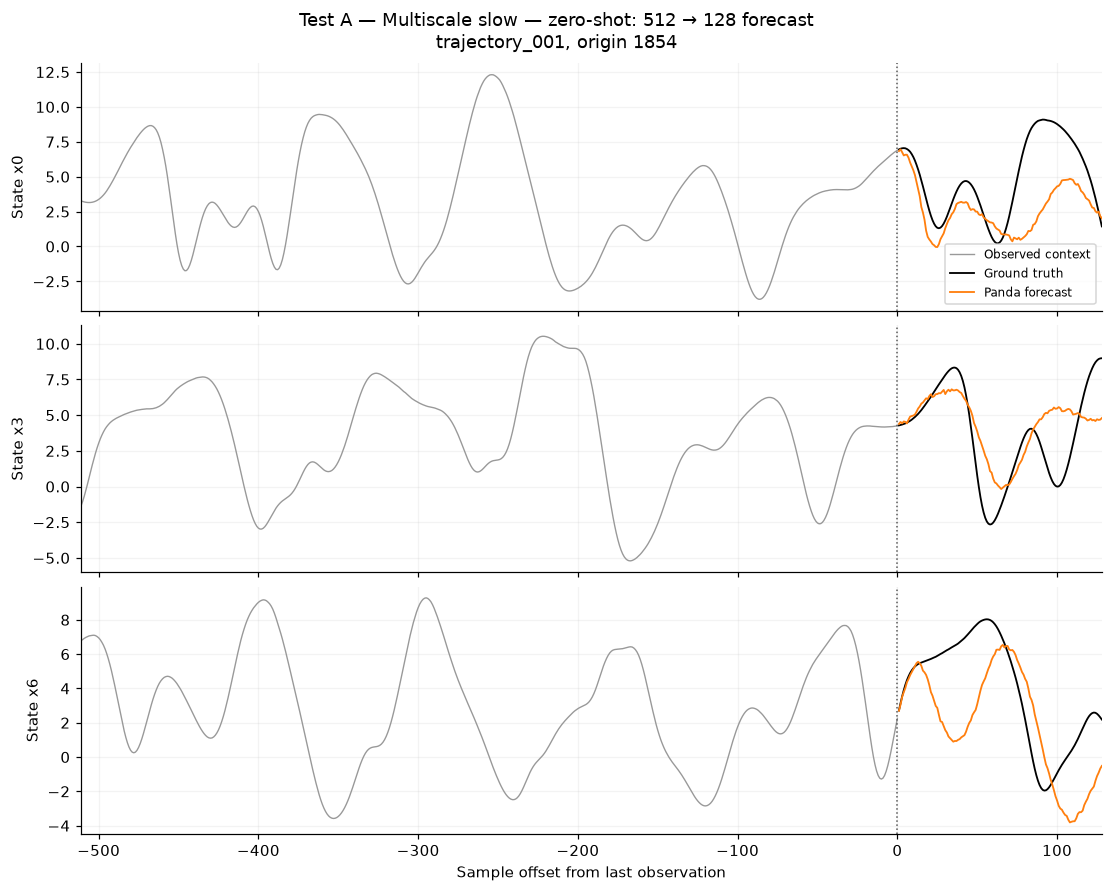

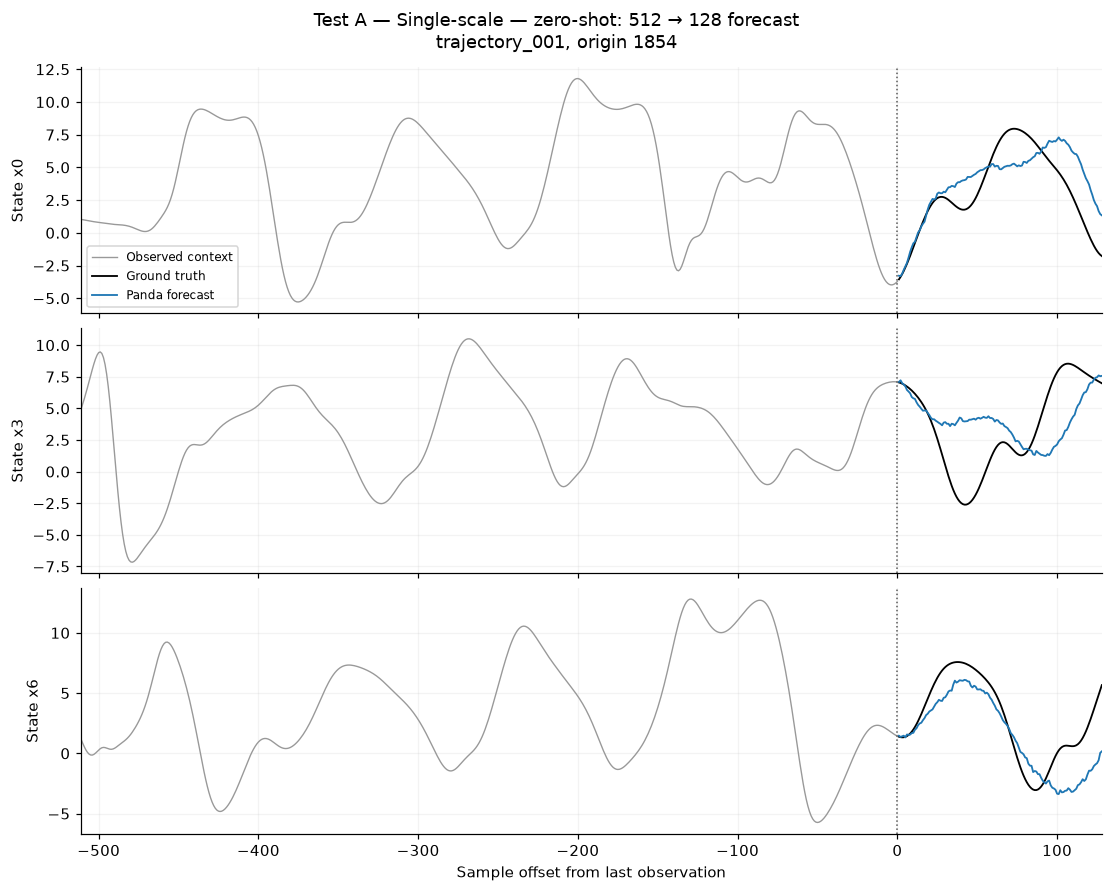

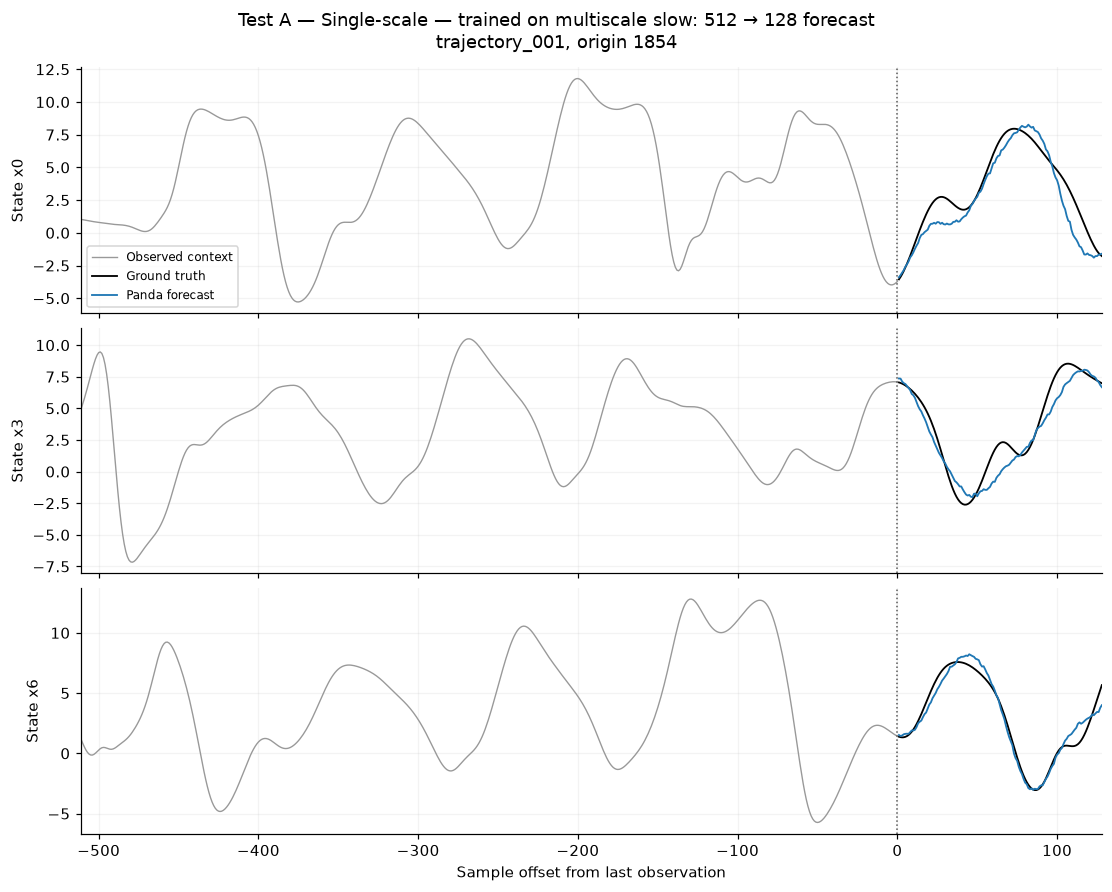

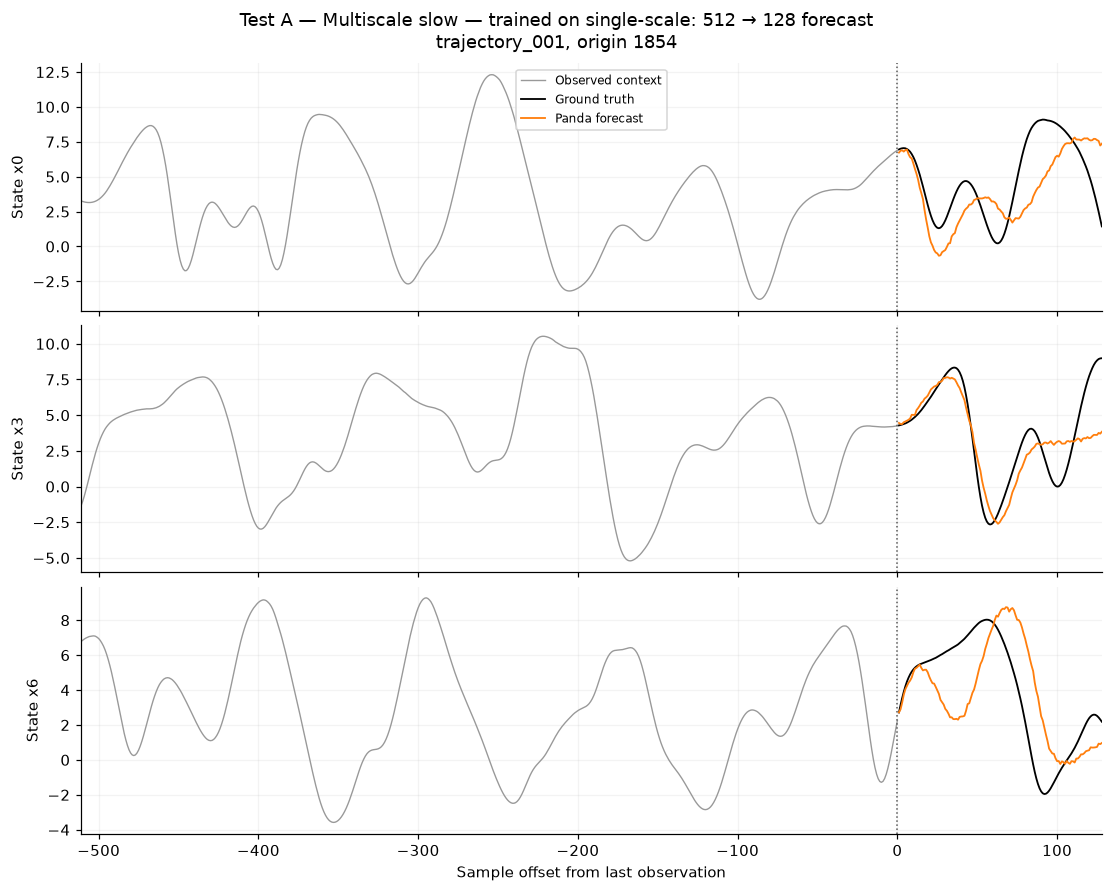

In [7]:
example_trajectory_index = 0
example_window_index = 0
display_channels = [0, 3, 6]
context_leads = np.arange(-context_length + 1, 1)

for case, spec in evaluation_cases.items():
    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
    result = results[case][example_trajectory_index]
    context = result["contexts"][example_window_index]
    target = result["targets"][example_window_index]
    prediction = result["predictions"][example_window_index]
    for axis, channel in zip(axes, display_channels):
        axis.plot(context_leads, context[:, channel], color="0.6", linewidth=0.9, label="Observed context")
        axis.plot(lead_times, target[:, channel], color="black", linewidth=1.2, label="Ground truth")
        axis.plot(lead_times, prediction[:, channel], color=spec["color"], linewidth=1.2, label="Panda forecast")
        axis.axvline(0, color="0.35", linestyle=":", linewidth=1)
        axis.set(ylabel=f"State x{channel}", xlim=(context_leads[0], prediction_length))
        axis.grid(alpha=0.15)
    axes[0].legend(fontsize=8)
    axes[-1].set_xlabel("Sample offset from last observation")
    fig.suptitle(
        f"Test A — {spec['label']}: 512 → 128 forecast\n"
        f"{result['trajectory_id']}, origin {result['origins'][example_window_index]}"
    )
    plt.show()


A state-space projection shows the same example window, using channels 0, 3, and 6. The final observed state is included as the start of both forecast segments to show continuity.


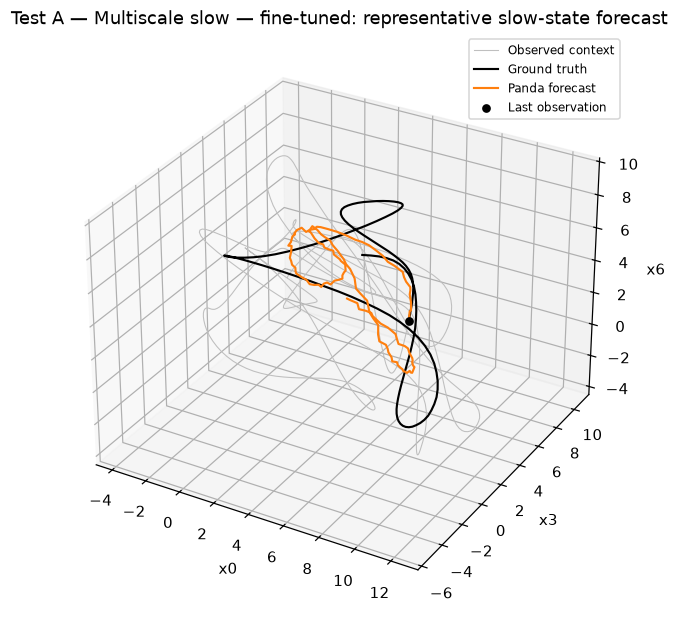

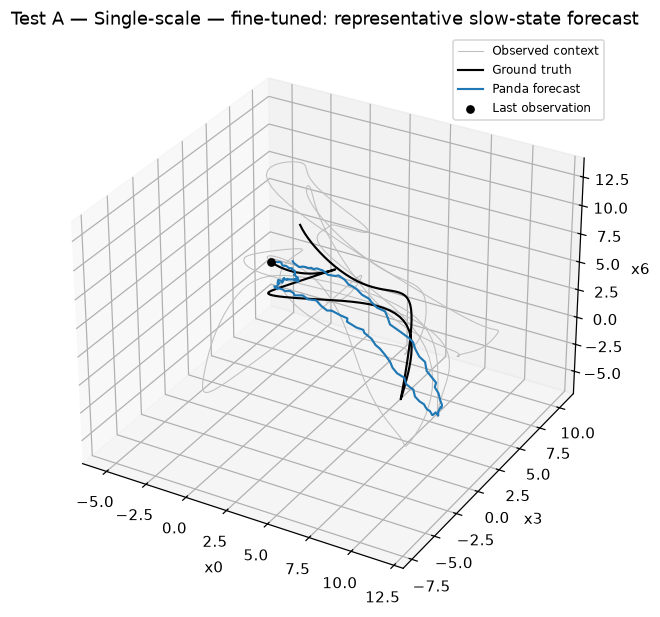

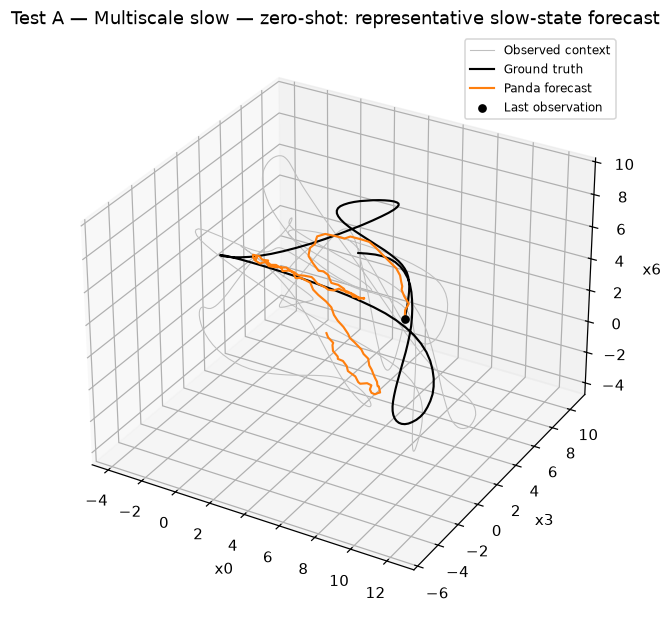

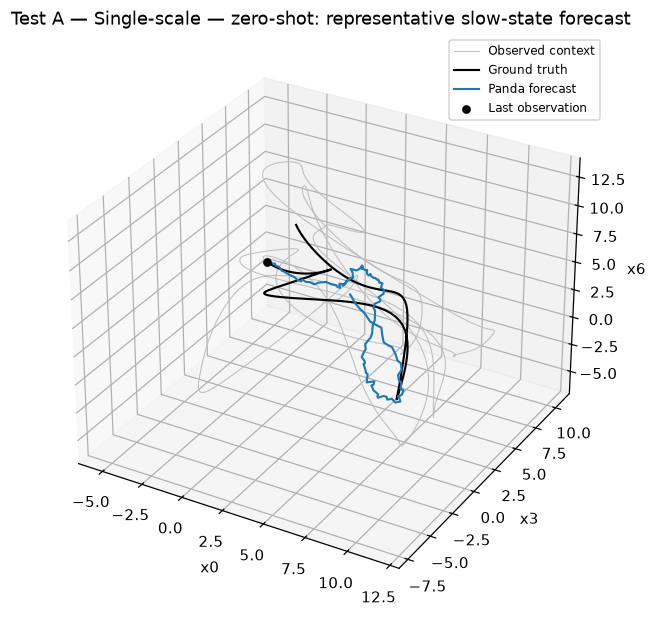

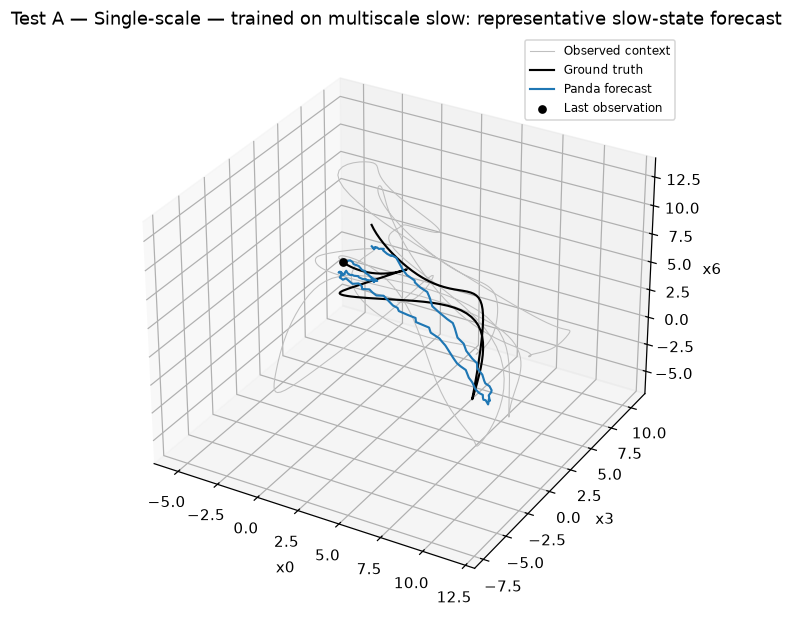

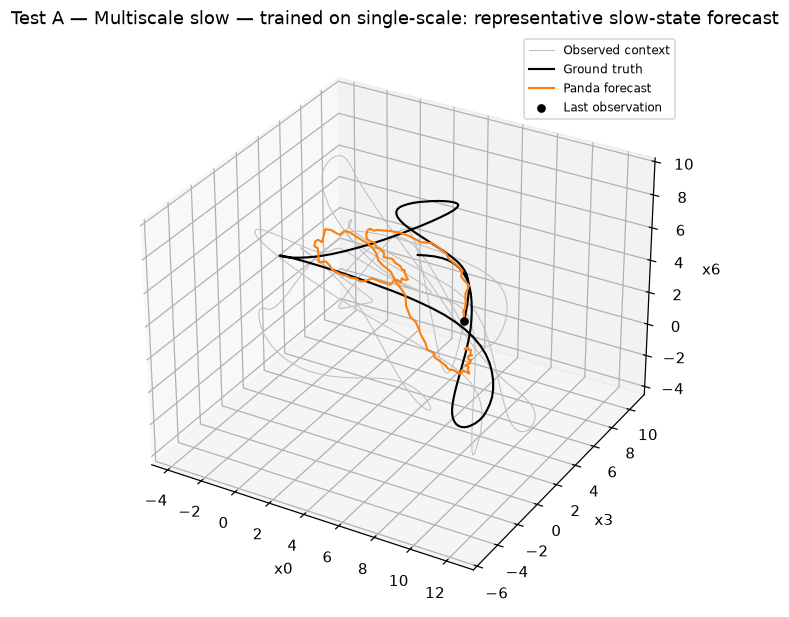

In [8]:
for case, spec in evaluation_cases.items():
    fig = plt.figure(figsize=(7, 5.5), constrained_layout=True)
    result = results[case][example_trajectory_index]
    context = result["contexts"][example_window_index]
    target = result["targets"][example_window_index]
    prediction = result["predictions"][example_window_index]
    axis = fig.add_subplot(1, 1, 1, projection="3d")
    axis.plot(*context[:, display_channels].T, color="0.75", linewidth=0.7, label="Observed context")
    truth_segment = np.vstack([context[-1], target])
    forecast_segment = np.vstack([context[-1], prediction])
    axis.plot(*truth_segment[:, display_channels].T, color="black", linewidth=1.4, label="Ground truth")
    axis.plot(*forecast_segment[:, display_channels].T, color=spec["color"], linewidth=1.4, label="Panda forecast")
    axis.scatter(*context[-1, display_channels], color="black", s=22, label="Last observation")
    axis.set(
        xlabel="x0", ylabel="x3", zlabel="x6",
        title=f"Test A — {spec['label']}: representative slow-state forecast",
    )
    axis.legend(fontsize=8)
    plt.show()


## 7. Variation across trajectories
Each bar averages the whole-window relative L2 error over six windows. Matching trajectory IDs share initialization lineage, but their targets and physical sampling intervals differ between the two dynamics.

Each model–data case is plotted separately; within-family, cross-family, and zero-shot bars refer to identical windows within a family.


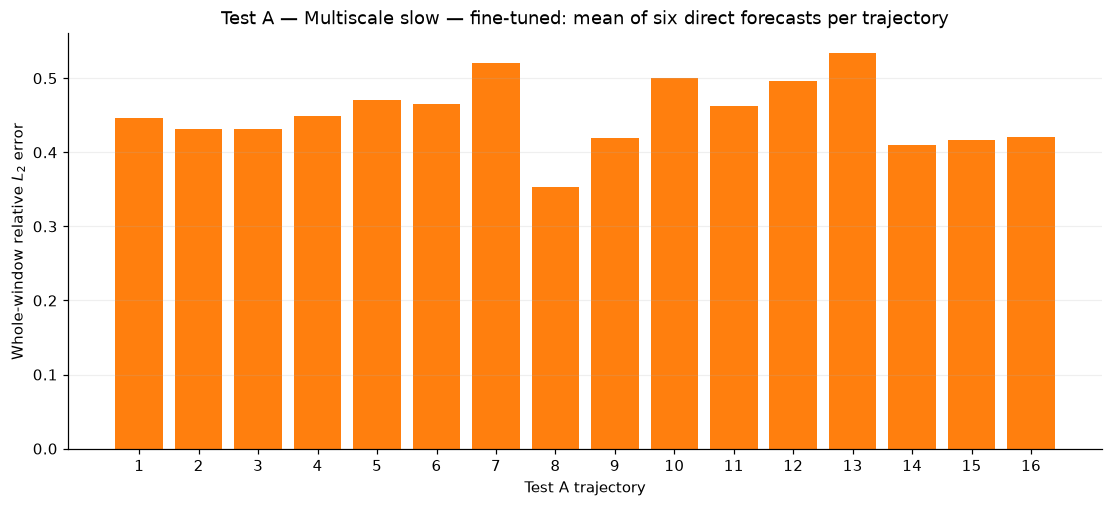

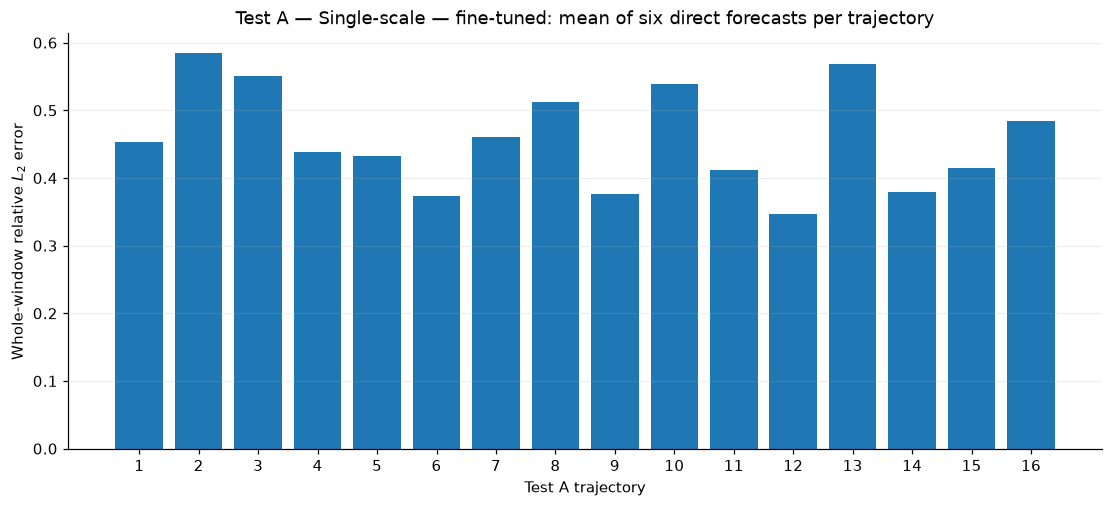

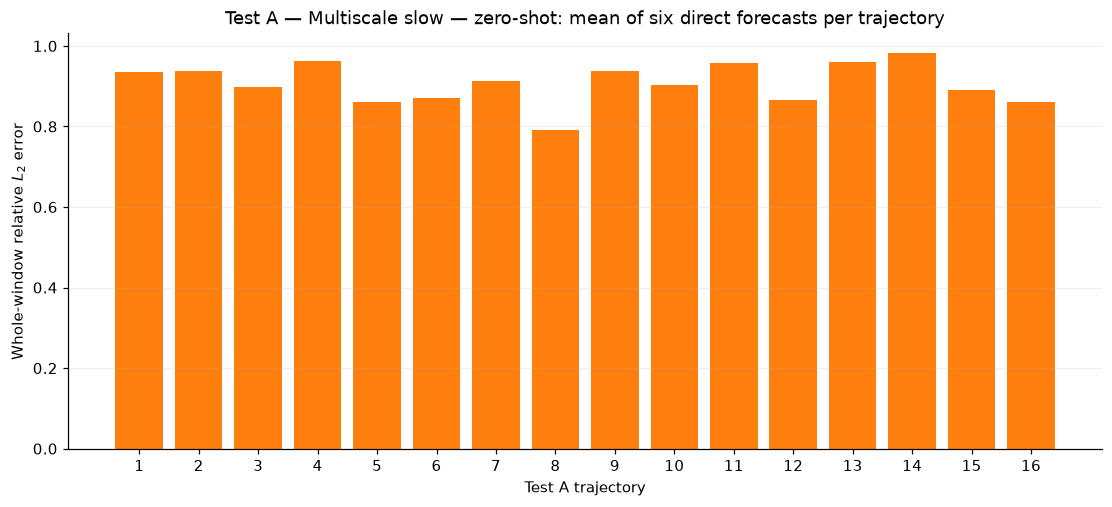

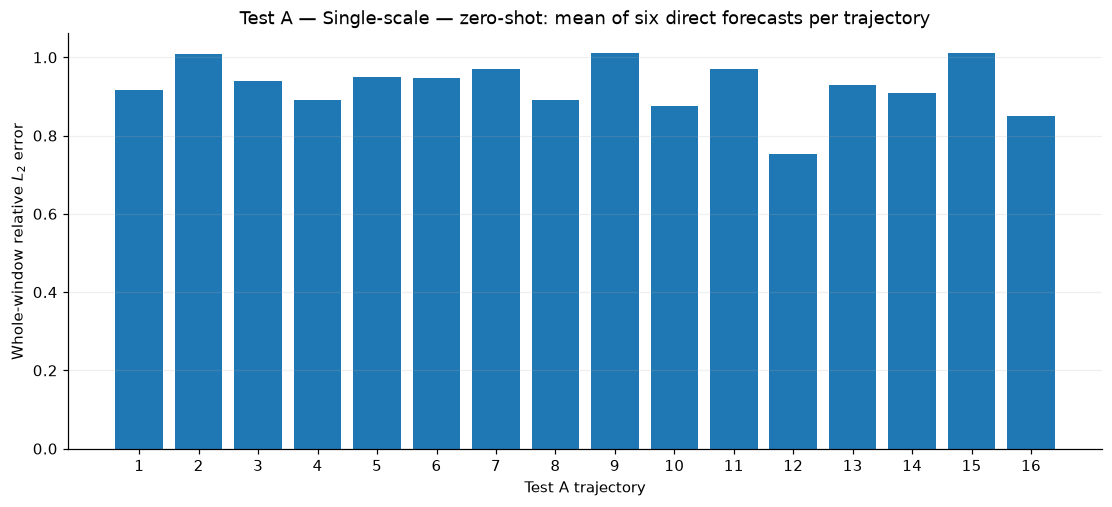

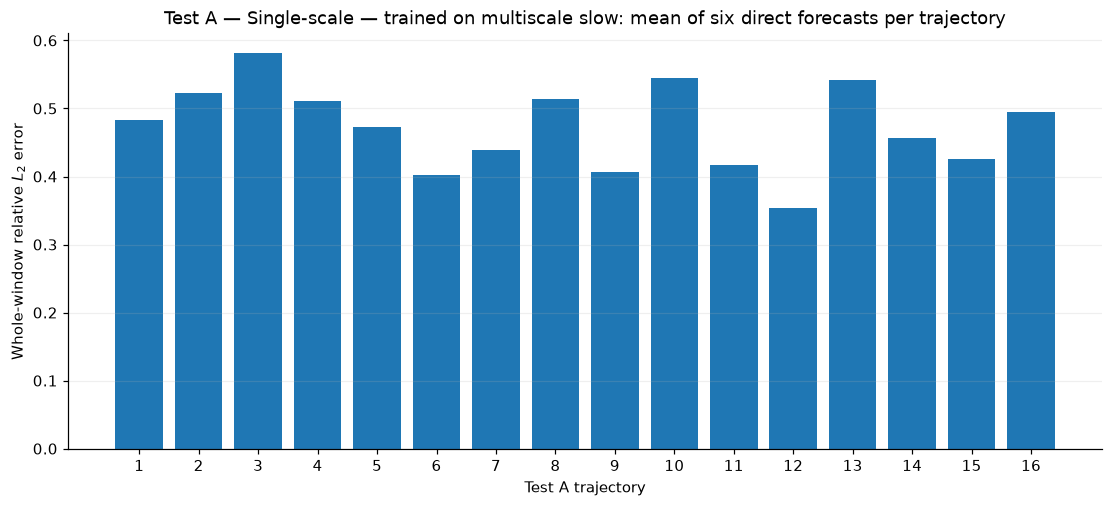

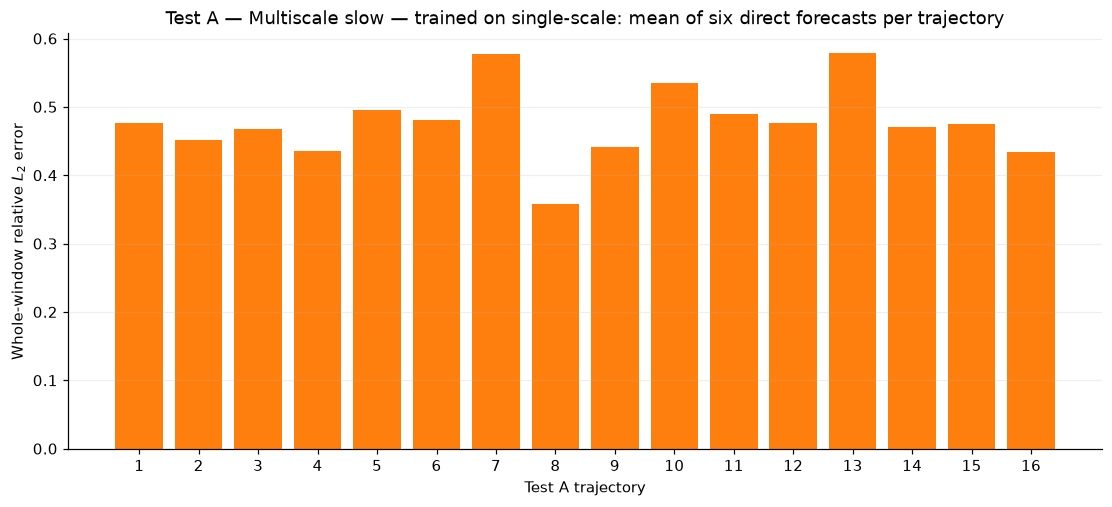

Window relative L2  ...  Lead 128 relative L2
Case                                      Trajectory                          ...                      
Multiscale slow — fine-tuned              trajectory_001              0.4463  ...                0.6826
                                          trajectory_002              0.4319  ...                0.5017
                                          trajectory_003              0.4314  ...                0.5136
                                          trajectory_004              0.4484  ...                0.6259
                                          trajectory_005              0.4706  ...                0.6566
...                                                                      ...  ...                   ...
Multiscale slow — trained on single-scale trajectory_012              0.4767  ...                0.7009
                                          trajectory_013              0.5787  ...                0.6632
                                          trajectory_014              0.4700  ...                0.6006
                                          trajectory_015              0.4746  ...                0.5813
                                          trajectory_016              0.4347  ...                0.6002

[96 rows x 3 columns]

In [9]:
for case, spec in evaluation_cases.items():
    values = trajectory_metrics.loc[
        trajectory_metrics["Case"] == spec["label"]
    ].set_index("Trajectory").reindex(trajectory_ids)["Window relative L2"]
    fig, axis = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
    axis.bar(np.arange(1, num_trajectories + 1), values, color=spec["color"])
    axis.set(
        xlabel="Test A trajectory", ylabel=r"Whole-window relative $L_2$ error",
        title=f"Test A — {spec['label']}: mean of six direct forecasts per trajectory",
        xticks=np.arange(1, num_trajectories + 1),
    )
    axis.grid(axis="y", alpha=0.2)
    plt.show()

display(trajectory_metrics.set_index(["Case", "Trajectory"]).round(4))


## 8. Test A summary
The table below reports whole-window relative L2 errors as **mean ± sample standard deviation across 16 trajectories**. This experiment measures direct short-term forecasting on held-out trajectories at the training configuration. It does not test parameter generalization, long-term stability, or prediction of fast states.

Within each family, fine-tuned and zero-shot models share identical targets, so their errors directly compare adaptation against the original checkpoint. Cross-family scores still refer to different target dynamics and sampling intervals.

The following transfer matrix fixes the test family by column and changes the training family by row. Its diagonal gives within-family results; off-diagonal entries give cross-family results.


In [10]:
formatted_report = pd.DataFrame(index=summary.index)
metric = "Window relative L2"
formatted_report[metric] = [
    f"{mean:.4f} ± {std:.4f}"
    for mean, std in zip(summary[(metric, "mean")], summary[(metric, "std")])
]
display(formatted_report)
print(f"Completed Test A: {num_trajectories} trajectories × {windows_per_trajectory} windows per case (six cases).")
print("Fine-tuned exports and the pinned original checkpoint were evaluated; no training was performed.")


Completed Test A: 16 trajectories × 6 windows per case (six cases).
Fine-tuned exports and the pinned original checkpoint were evaluated; no training was performed.


,Window relative L2
Case,
Multiscale slow — fine-tuned,0.4516 ± 0.0463
Single-scale — fine-tuned,0.4579 ± 0.0750
Multiscale slow — zero-shot,0.9082 ± 0.0503
Single-scale — zero-shot,0.9263 ± 0.0671
Single-scale — trained on multiscale slow,0.4731 ± 0.0624
Multiscale slow — trained on single-scale,0.4777 ± 0.0541


In [11]:
# Hold the test family fixed within each column when comparing checkpoints
fine_tuned_cases = {
    case: spec for case, spec in evaluation_cases.items() if spec["model_kind"] == "finetuned"
}
family_labels = [spec["label"] for spec in families.values()]
test_a_transfer = pd.DataFrame(index=family_labels, columns=family_labels, dtype=float)
for case, spec in fine_tuned_cases.items():
    training_label = families[spec["training_family"]]["label"]
    test_label = families[spec["family"]]["label"]
    test_a_transfer.loc[training_label, test_label] = summary.loc[
        spec["label"], ("Window relative L2", "mean")
    ]
test_a_transfer.index.name = "Training family"
test_a_transfer.columns.name = "Test family"
print("Test A: mean whole-window relative L2 (16 trajectories, six windows each)")
display(test_a_transfer.round(4))


Test A: mean whole-window relative L2 (16 trajectories, six windows each)


Test family,Multiscale slow,Single-scale
Training family,,
Multiscale slow,0.4516,0.4731
Single-scale,0.4777,0.4579


## 9. Test B: one-parameter generalization
Keep the two fine-tuned models and the original zero-shot model frozen and evaluate all five held-out configurations. Each test family is predicted by both fine-tuned checkpoints and the original checkpoint. **No retraining or checkpoint selection uses Test B.**

| Subset | Changed parameter | Slow channels |
|---|---|---:|
| B-K | K = 18 | 18 |
| B-J | J = 16 | 9 |
| B-hx | hx = -1.2 | 9 |
| B-hy | hy = 1.4 | 9 |
| B-F | F = 14 | 9 |

Each subset contains four trajectories per family. Use six fixed-seed windows per trajectory, giving 24 forecasts per case per subset. Matching trajectory IDs use the same window indices across families. The 512→128 protocol, float32 inference, and repository relative L2 metric are unchanged. Errors include **all slow channels**, including all 18 channels in B-K; fast states are never loaded.


In [12]:
test_b_specs = {
    "b_k": {"label": "B-K: K = 18", "channels": 18},
    "b_j": {"label": "B-J: J = 16", "channels": 9},
    "b_hx": {"label": "B-hx: hx = -1.2", "channels": 9},
    "b_hy": {"label": "B-hy: hy = 1.4", "channels": 9},
    "b_f": {"label": "B-F: F = 14", "channels": 9},
}
test_b_ids = [f"trajectory_{index:03d}" for index in range(1, 5)]
test_b_data = {}
test_b_origins = {}
test_b_protocol = []
for subset_index, (subset, subset_spec) in enumerate(test_b_specs.items(), start=1):
    test_b_data[subset] = {}
    test_b_origins[subset] = {}
    for trajectory_index, trajectory_id in enumerate(test_b_ids):
        rng = np.random.default_rng(np.random.SeedSequence([window_seed, subset_index, trajectory_index]))
        test_b_origins[subset][trajectory_id] = np.sort(
            rng.choice(
                np.arange(context_length, 8192 - prediction_length + 1),
                size=windows_per_trajectory, replace=False,
            )
        )
    for family, spec in families.items():
        source = data_root / family / subset
        if family == "multiscale":
            source = source / "slow_downsampled"
        paths = sorted(source.glob("trajectory_*.npz"))
        if [path.stem for path in paths] != test_b_ids:
            raise ValueError(f"Expected four Test B trajectories in {source}")
        trajectories = []
        for path in paths:
            with np.load(path, allow_pickle=False) as archive:
                time = archive["time"].copy()
                state = archive["slow_states"].T.copy()
            if time.shape != (8192,) or state.shape != (8192, subset_spec["channels"]):
                raise ValueError(f"Unexpected Test B dimensions in {path}")
            if not np.isfinite(time).all() or not np.isfinite(state).all():
                raise ValueError(f"Nonfinite Test B values in {path}")
            intervals = np.diff(time)
            if not np.all(intervals > 0) or not np.allclose(intervals, intervals[0], rtol=1e-7, atol=0):
                raise ValueError(f"Expected a uniform increasing time grid in {path}")
            trajectories.append({"id": path.stem, "time": time, "state": state})
        test_b_data[subset][family] = trajectories
        test_b_protocol.append({
            "Subset": subset_spec["label"], "Family": spec["label"],
            "Trajectories": len(trajectories), "Forecasts": len(trajectories) * windows_per_trajectory,
            "Channels": subset_spec["channels"],
            "Sample interval": float(trajectories[0]["time"][1] - trajectories[0]["time"][0]),
        })
display(pd.DataFrame(test_b_protocol).set_index(["Subset", "Family"]))


Trajectories  ...  Sample interval
Subset          Family                         ...                 
B-K: K = 18     Multiscale slow             4  ...         0.013355
                Single-scale                4  ...         0.014045
B-J: J = 16     Multiscale slow             4  ...         0.013242
                Single-scale                4  ...         0.013706
B-hx: hx = -1.2 Multiscale slow             4  ...         0.014810
                Single-scale                4  ...         0.015547
B-hy: hy = 1.4  Multiscale slow             4  ...         0.014269
                Single-scale                4  ...         0.014013
B-F: F = 14     Multiscale slow             4  ...         0.010314
                Single-scale                4  ...         0.010113

[10 rows x 4 columns]

### 9.1 Direct forecasts with frozen models
Load each evaluation model and run it on the five corresponding Test B datasets. Both fine-tuned checkpoints and the zero-shot model see the same windows and targets within each family. B-K changes the number of input and output channels to 18; the context and forecast lengths stay 512 and 128.


In [13]:
test_b_results = {subset: {} for subset in test_b_specs}
test_b_inference_rows = []
for case, spec in evaluation_cases.items():
    model = load_evaluation_model(spec)

    for subset, subset_spec in test_b_specs.items():
        start = perf_counter()
        subset_results = []
        for trajectory in tqdm(
            test_b_data[subset][spec["family"]], desc=f"{subset_spec['label']} / {spec['label']}", unit="trajectory",
        ):
            origins = test_b_origins[subset][trajectory["id"]]
            contexts = np.stack([
                trajectory["state"][origin - context_length:origin] for origin in origins
            ]).astype(np.float32)
            targets = np.stack([
                trajectory["state"][origin:origin + prediction_length] for origin in origins
            ])
            batches = []
            with torch.inference_mode():
                for first in range(0, windows_per_trajectory, batch_size):
                    past = torch.from_numpy(contexts[first:first + batch_size]).to(device)
                    predictions = model(
                        past_values=past,
                        past_observed_mask=torch.ones_like(past, dtype=torch.bool),
                        return_dict=True,
                    ).prediction_outputs
                    batches.append(predictions.cpu().numpy())
            predictions = np.concatenate(batches)
            if predictions.shape != targets.shape or not np.isfinite(predictions).all():
                raise ValueError(f"Invalid predictions for {subset}/{case}/{trajectory['id']}")
            subset_results.append({
                "trajectory_id": trajectory["id"], "origins": origins.copy(),
                "contexts": contexts, "targets": targets, "predictions": predictions,
            })
        test_b_results[subset][case] = subset_results
        test_b_inference_rows.append({
            "Subset": subset_spec["label"], "Case": spec["label"],
            "Forecasts": len(subset_results) * windows_per_trajectory,
            "Inference seconds": perf_counter() - start,
        })
    del model, past, predictions
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()
display(pd.DataFrame(test_b_inference_rows).set_index(["Subset", "Case"]))


,,Forecasts,Inference seconds
Subset,Case,,
B-K: K = 18,Multiscale slow — fine-tuned,24,1.064831
B-J: J = 16,Multiscale slow — fine-tuned,24,0.611438
B-hx: hx = -1.2,Multiscale slow — fine-tuned,24,0.601276
B-hy: hy = 1.4,Multiscale slow — fine-tuned,24,0.594822
B-F: F = 14,Multiscale slow — fine-tuned,24,0.605205
B-K: K = 18,Single-scale — fine-tuned,24,1.079131
B-J: J = 16,Single-scale — fine-tuned,24,0.639759
B-hx: hx = -1.2,Single-scale — fine-tuned,24,0.641143
B-hy: hy = 1.4,Single-scale — fine-tuned,24,0.608028


B-F: F = 14 / Single-scale — fine-tuned: 100%|##########| 4/4 [00:00<00:00,  6.30trajectory/s]
/opt/homebrew/Caskroom/miniconda/base/envs/panda/lib/python3.11/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
B-F: F = 14 / Single-scale — zero-shot: 100%|##########| 4/4 [00:00<00:00,  5.67trajectory/s]
B-K: K = 18 / Single-scale — trained on multiscale slow: 100%|##########| 4/4 [00:01<00:00,  3.66trajectory/s]
B-J: J = 16 / Single-scale — trained on multiscale slow: 100%|##########| 4/4 [00:00<00:00,  6.25trajectory/s]
B-hx: hx = -1.2 / Single-scale — trained on multiscale slow: 100%|##########| 4/4 [00:00<00:00,  6.05trajectory/s]
B-hy: hy = 1.4 / Single-scale — trained on multiscale slow: 100%|##########| 4/4 [00:00<00:00,  5.91trajectory/s]
B-F: F = 14 / Single-scale — trained on

### 9.2 Relative L2 results
Use `src.evaluation.relative_l2_error` for both whole-window and per-lead errors. Average windows within each trajectory first. Each mean and sample standard deviation below therefore uses **four trajectory-level values**. The subset-specific sampling intervals and target dynamics differ, so these are task-specific error summaries, not a comparison on identical targets.

Fine-tuned versus zero-shot comparisons within each family use identical targets.


In [14]:
test_b_rows = []
test_b_error_curves = {subset: {} for subset in test_b_specs}
for subset, subset_spec in test_b_specs.items():
    for case, spec in evaluation_cases.items():
        curves = []
        for result in test_b_results[subset][case]:
            relative_by_lead = relative_l2_error(result["targets"], result["predictions"], axis=-1)
            window_relative_l2 = relative_l2_error(result["targets"], result["predictions"], axis=(1, 2))
            if not np.isfinite(relative_by_lead).all() or not np.isfinite(window_relative_l2).all():
                raise ValueError("Relative L2 requires nonzero target norms for this summary")
            curves.append(relative_by_lead.mean(axis=0))
            test_b_rows.append({
                "Subset": subset_spec["label"], "Case": spec["label"],
                "Trajectory": result["trajectory_id"],
                "Window relative L2": window_relative_l2.mean(),
                "Mean lead relative L2": relative_by_lead.mean(),
                "Lead 128 relative L2": relative_by_lead[:, -1].mean(),
            })
        test_b_error_curves[subset][case] = np.stack(curves)

test_b_metrics = pd.DataFrame(test_b_rows)
test_b_summary = test_b_metrics.groupby(["Subset", "Case"], sort=False)[metric_columns].agg(["mean", "std"])
display(test_b_summary.round(4))

test_b_report = pd.DataFrame(index=test_b_summary.index)
for metric in metric_columns:
    test_b_report[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(test_b_summary[(metric, "mean")], test_b_summary[(metric, "std")])
    ]
display(test_b_report)


Window relative L2  ... Lead 128 relative L2
                                                                        mean  ...                  std
Subset          Case                                                          ...                     
B-K: K = 18     Multiscale slow — fine-tuned                          0.7083  ...               0.0492
                Single-scale — fine-tuned                             0.7177  ...               0.0532
                Multiscale slow — zero-shot                           1.0187  ...               0.0407
                Single-scale — zero-shot                              0.9835  ...               0.0826
                Single-scale — trained on multiscale slow             0.6946  ...               0.0469
                Multiscale slow — trained on single-scale             0.7180  ...               0.0549
B-J: J = 16     Multiscale slow — fine-tuned                          0.4556  ...               0.0532
                Single-scale — fine-tuned                             0.5112  ...               0.0791
                Multiscale slow — zero-shot                           0.9138  ...               0.1563
                Single-scale — zero-shot                              0.9604  ...               0.1097
                Single-scale — trained on multiscale slow             0.5176  ...               0.0427
                Multiscale slow — trained on single-scale             0.4224  ...               0.0811
B-hx: hx = -1.2 Multiscale slow — fine-tuned                          0.4115  ...               0.0533
                Single-scale — fine-tuned                             0.4972  ...               0.0538
                Multiscale slow — zero-shot                           0.7845  ...               0.1020
                Single-scale — zero-shot                              0.8422  ...               0.0392
                Single-scale — trained on multiscale slow             0.4979  ...               0.0399
                Multiscale slow — trained on single-scale             0.4932  ...               0.0606
B-hy: hy = 1.4  Multiscale slow — fine-tuned                          0.4364  ...               0.0351
                Single-scale — fine-tuned                             0.4310  ...               0.0573
                Multiscale slow — zero-shot                           0.8781  ...               0.1469
                Single-scale — zero-shot                              0.8606  ...               0.0998
                Single-scale — trained on multiscale slow             0.4544  ...               0.0653
                Multiscale slow — trained on single-scale             0.4760  ...               0.0340
B-F: F = 14     Multiscale slow — fine-tuned                          0.7325  ...               0.1199
                Single-scale — fine-tuned                             0.7178  ...               0.0827
                Multiscale slow — zero-shot                           0.9689  ...               0.0823
                Single-scale — zero-shot                              1.0605  ...               0.1924
                Single-scale — trained on multiscale slow             0.7180  ...               0.0962
                Multiscale slow — trained on single-scale             0.7395  ...               0.1449

[30 rows x 6 columns]

Window relative L2  ... Lead 128 relative L2
Subset          Case                                                          ...                     
B-K: K = 18     Multiscale slow — fine-tuned                 0.7083 ± 0.0352  ...      0.8341 ± 0.0492
                Single-scale — fine-tuned                    0.7177 ± 0.0308  ...      0.8471 ± 0.0532
                Multiscale slow — zero-shot                  1.0187 ± 0.0289  ...      1.1504 ± 0.0407
                Single-scale — zero-shot                     0.9835 ± 0.0061  ...      1.1426 ± 0.0826
                Single-scale — trained on multiscale slow    0.6946 ± 0.0226  ...      0.8330 ± 0.0469
                Multiscale slow — trained on single-scale    0.7180 ± 0.0278  ...      0.8687 ± 0.0549
B-J: J = 16     Multiscale slow — fine-tuned                 0.4556 ± 0.0477  ...      0.6039 ± 0.0532
                Single-scale — fine-tuned                    0.5112 ± 0.0585  ...      0.7126 ± 0.0791
                Multiscale slow — zero-shot                  0.9138 ± 0.0496  ...      1.0556 ± 0.1563
                Single-scale — zero-shot                     0.9604 ± 0.0644  ...      1.0441 ± 0.1097
                Single-scale — trained on multiscale slow    0.5176 ± 0.0570  ...      0.6939 ± 0.0427
                Multiscale slow — trained on single-scale    0.4224 ± 0.0335  ...      0.5768 ± 0.0811
B-hx: hx = -1.2 Multiscale slow — fine-tuned                 0.4115 ± 0.0419  ...      0.6170 ± 0.0533
                Single-scale — fine-tuned                    0.4972 ± 0.0376  ...      0.7734 ± 0.0538
                Multiscale slow — zero-shot                  0.7845 ± 0.0807  ...      1.0518 ± 0.1020
                Single-scale — zero-shot                     0.8422 ± 0.0250  ...      1.0444 ± 0.0392
                Single-scale — trained on multiscale slow    0.4979 ± 0.0302  ...      0.7240 ± 0.0399
                Multiscale slow — trained on single-scale    0.4932 ± 0.0520  ...      0.7959 ± 0.0606
B-hy: hy = 1.4  Multiscale slow — fine-tuned                 0.4364 ± 0.0693  ...      0.5821 ± 0.0351
                Single-scale — fine-tuned                    0.4310 ± 0.0609  ...      0.5737 ± 0.0573
                Multiscale slow — zero-shot                  0.8781 ± 0.0982  ...      1.0354 ± 0.1469
                Single-scale — zero-shot                     0.8606 ± 0.0942  ...      1.0185 ± 0.0998
                Single-scale — trained on multiscale slow    0.4544 ± 0.0722  ...      0.5933 ± 0.0653
                Multiscale slow — trained on single-scale    0.4760 ± 0.0614  ...      0.6430 ± 0.0340
B-F: F = 14     Multiscale slow — fine-tuned                 0.7325 ± 0.1412  ...      0.9141 ± 0.1199
                Single-scale — fine-tuned                    0.7178 ± 0.0538  ...      0.9080 ± 0.0827
                Multiscale slow — zero-shot                  0.9689 ± 0.1106  ...      1.1995 ± 0.0823
                Single-scale — zero-shot                     1.0605 ± 0.0728  ...      1.2256 ± 0.1924
                Single-scale — trained on multiscale slow    0.7180 ± 0.0426  ...      0.8866 ± 0.0962
                Multiscale slow — trained on single-scale    0.7395 ± 0.1349  ...      0.9550 ± 0.1449

[30 rows x 3 columns]

In [15]:
test_b_transfer_rows = []
for subset, subset_spec in test_b_specs.items():
    for training_family, training_spec in families.items():
        row = {"Subset": subset_spec["label"], "Training family": training_spec["label"]}
        for case, spec in fine_tuned_cases.items():
            if spec["training_family"] == training_family:
                row[families[spec["family"]]["label"]] = test_b_summary.loc[
                    (subset_spec["label"], spec["label"]), ("Window relative L2", "mean")
                ]
        test_b_transfer_rows.append(row)
test_b_transfer = pd.DataFrame(test_b_transfer_rows).set_index(["Subset", "Training family"])
test_b_transfer.columns.name = "Test family"
print("Test B: mean whole-window relative L2 (four trajectories, six windows each)")
display(test_b_transfer.round(4))


Test B: mean whole-window relative L2 (four trajectories, six windows each)


Test family                      Multiscale slow  Single-scale
Subset          Training family                               
B-K: K = 18     Multiscale slow           0.7083        0.6946
                Single-scale              0.7180        0.7177
B-J: J = 16     Multiscale slow           0.4556        0.5176
                Single-scale              0.4224        0.5112
B-hx: hx = -1.2 Multiscale slow           0.4115        0.4979
                Single-scale              0.4932        0.4972
B-hy: hy = 1.4  Multiscale slow           0.4364        0.4544
                Single-scale              0.4760        0.4310
B-F: F = 14     Multiscale slow           0.7325        0.7180
                Single-scale              0.7395        0.7178

### 9.3 Separate figures for each subset and model–data case
Each subset has six separate figures, one for each model–data case. The first three panels show the preselected example (trajectory 001, first selected window) in channels 0, 3, and 6. The final panel shows relative L2 error over **all slow channels**: median and IQR across the four trajectory-level curves, each averaging six windows. No figure combines multiscale and single-scale results.


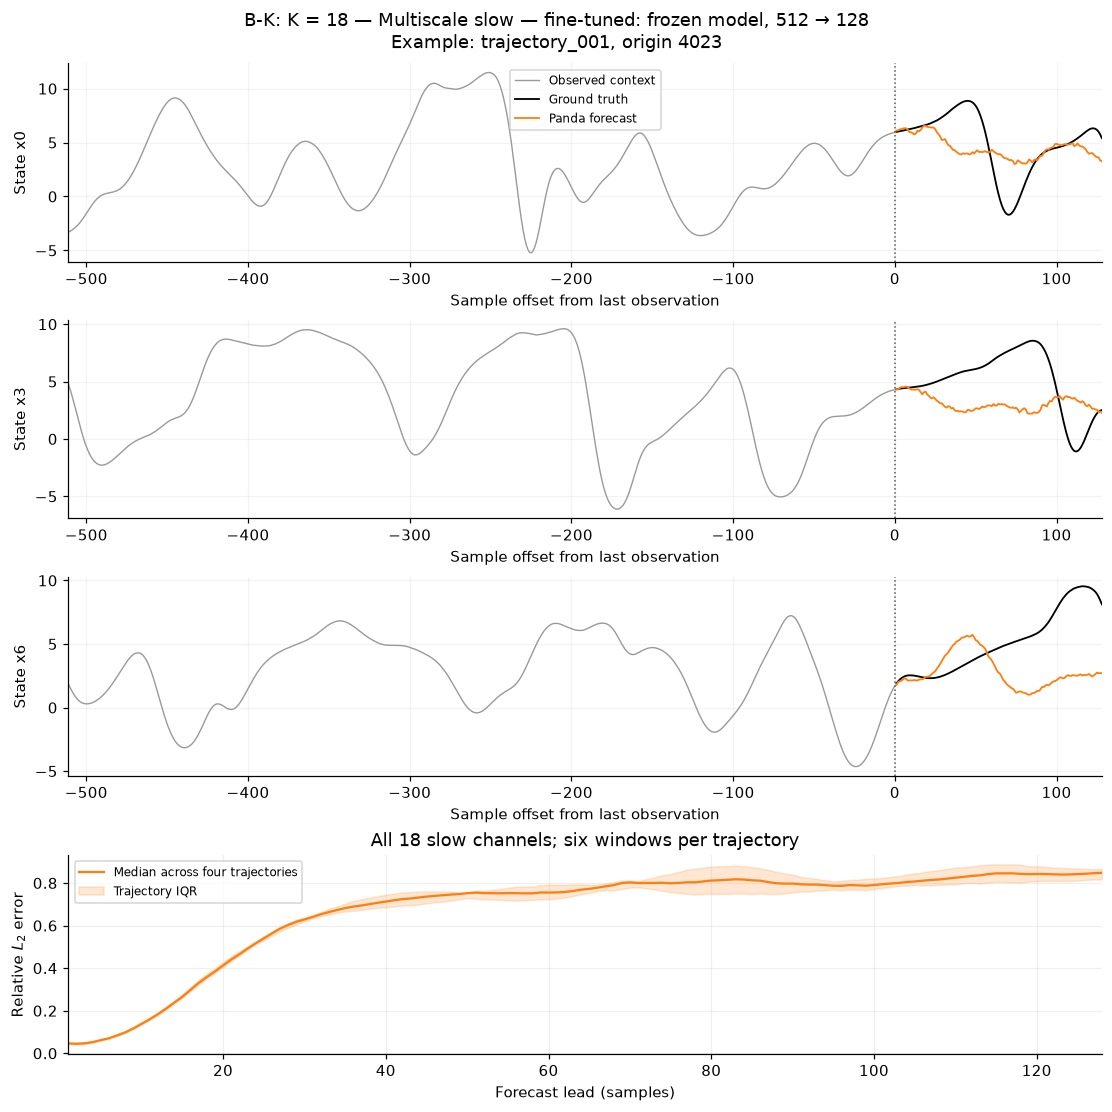

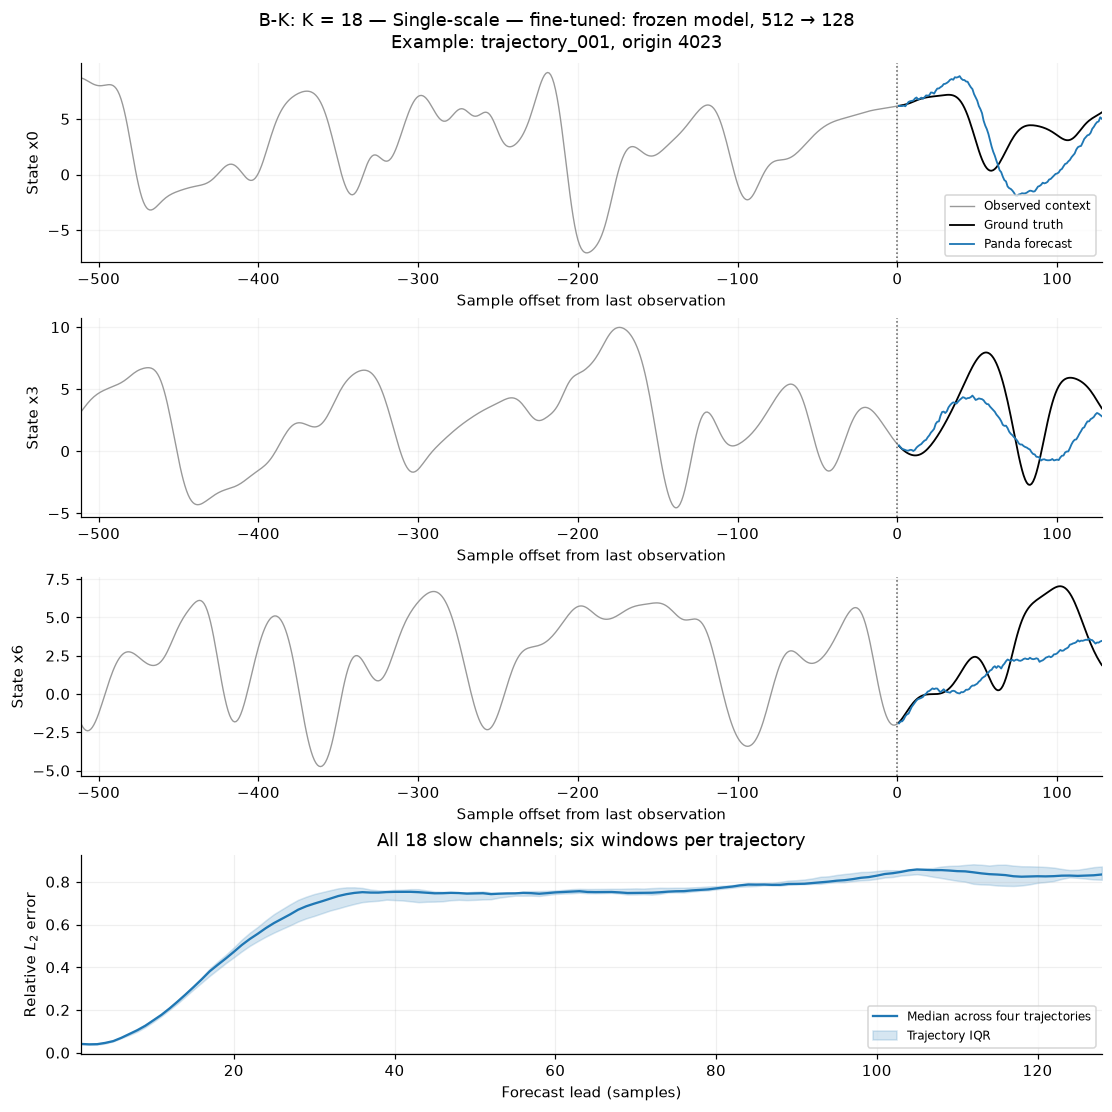

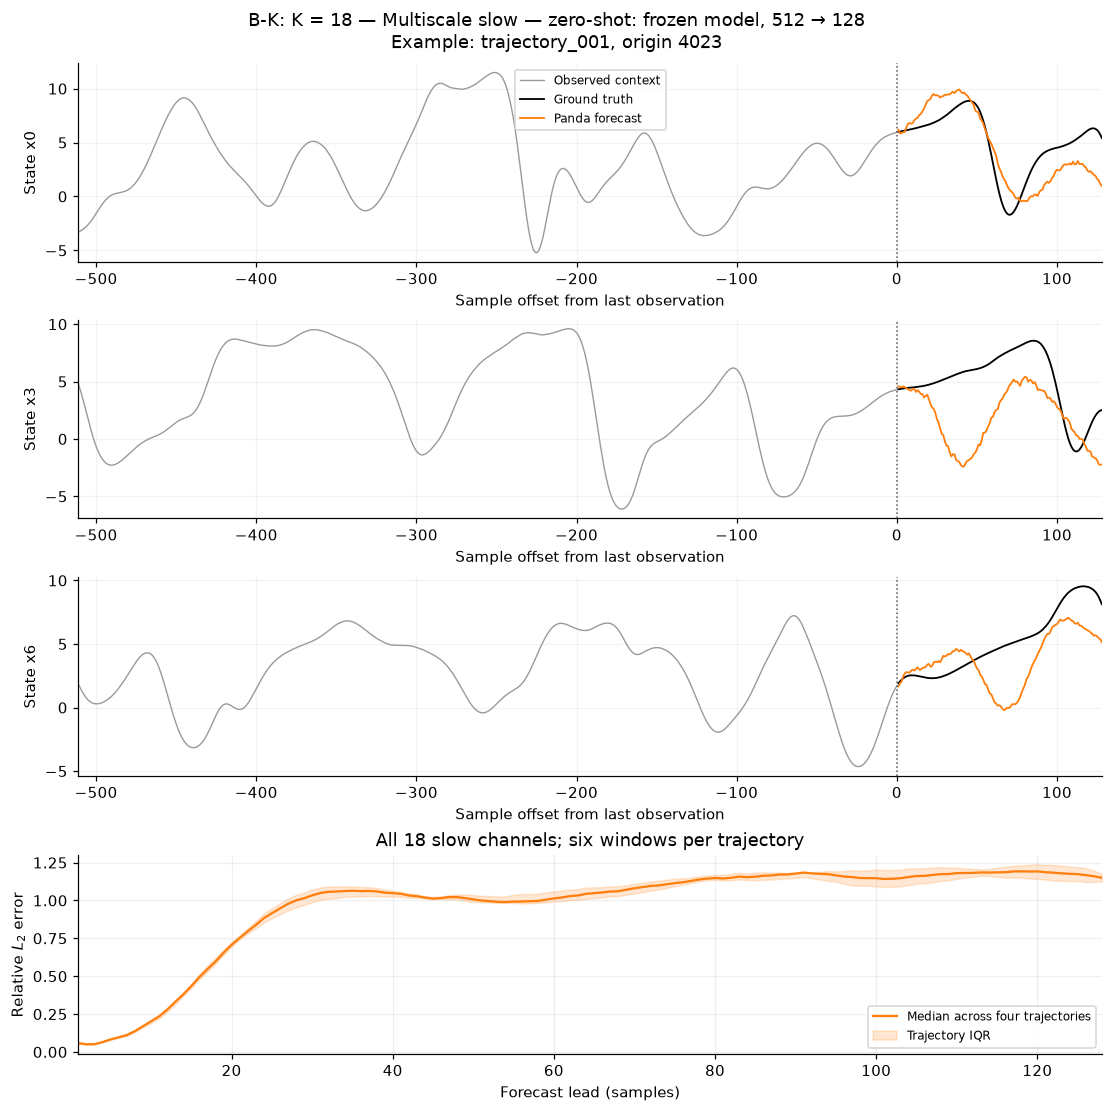

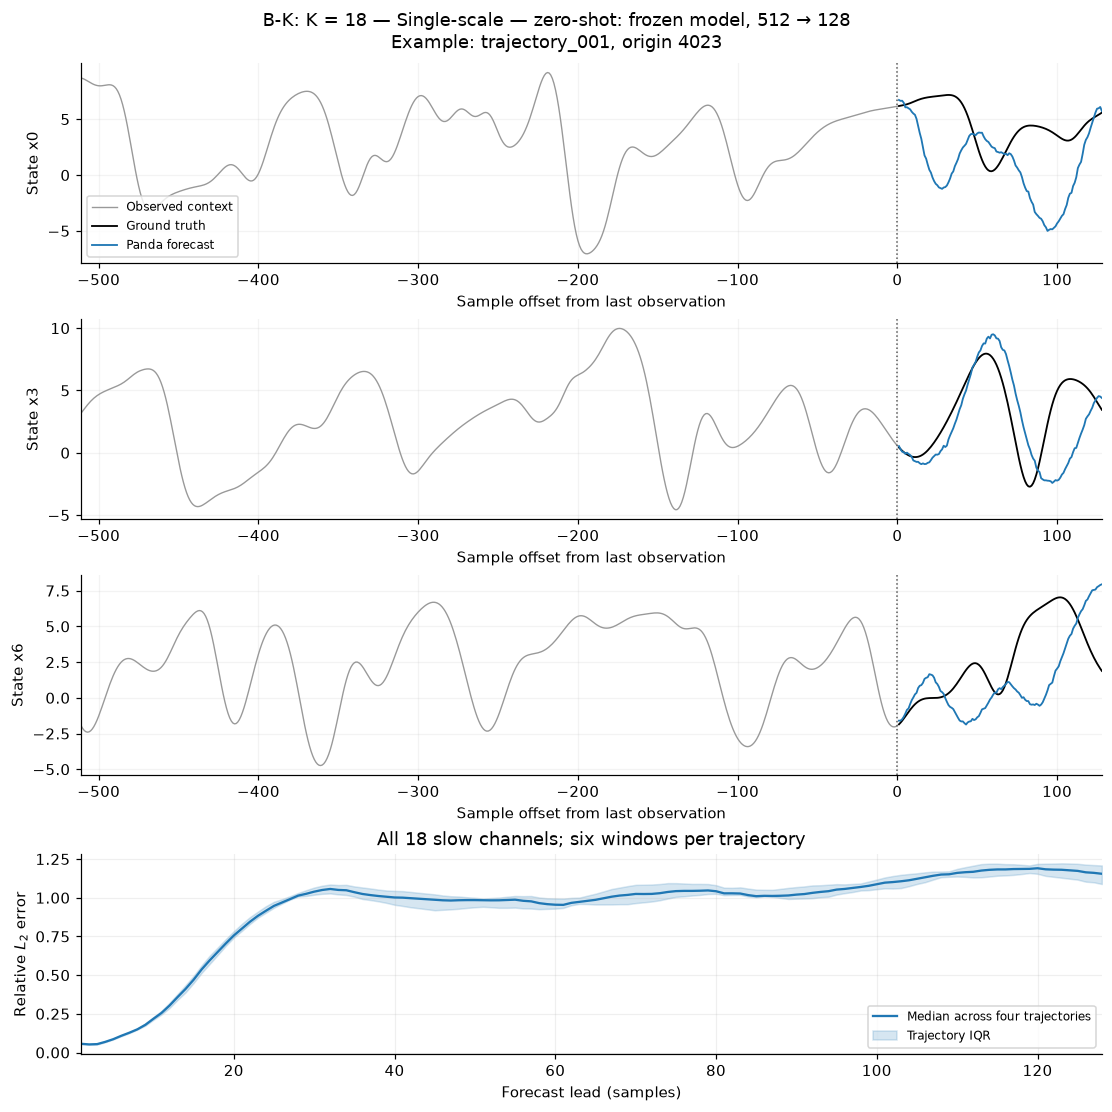

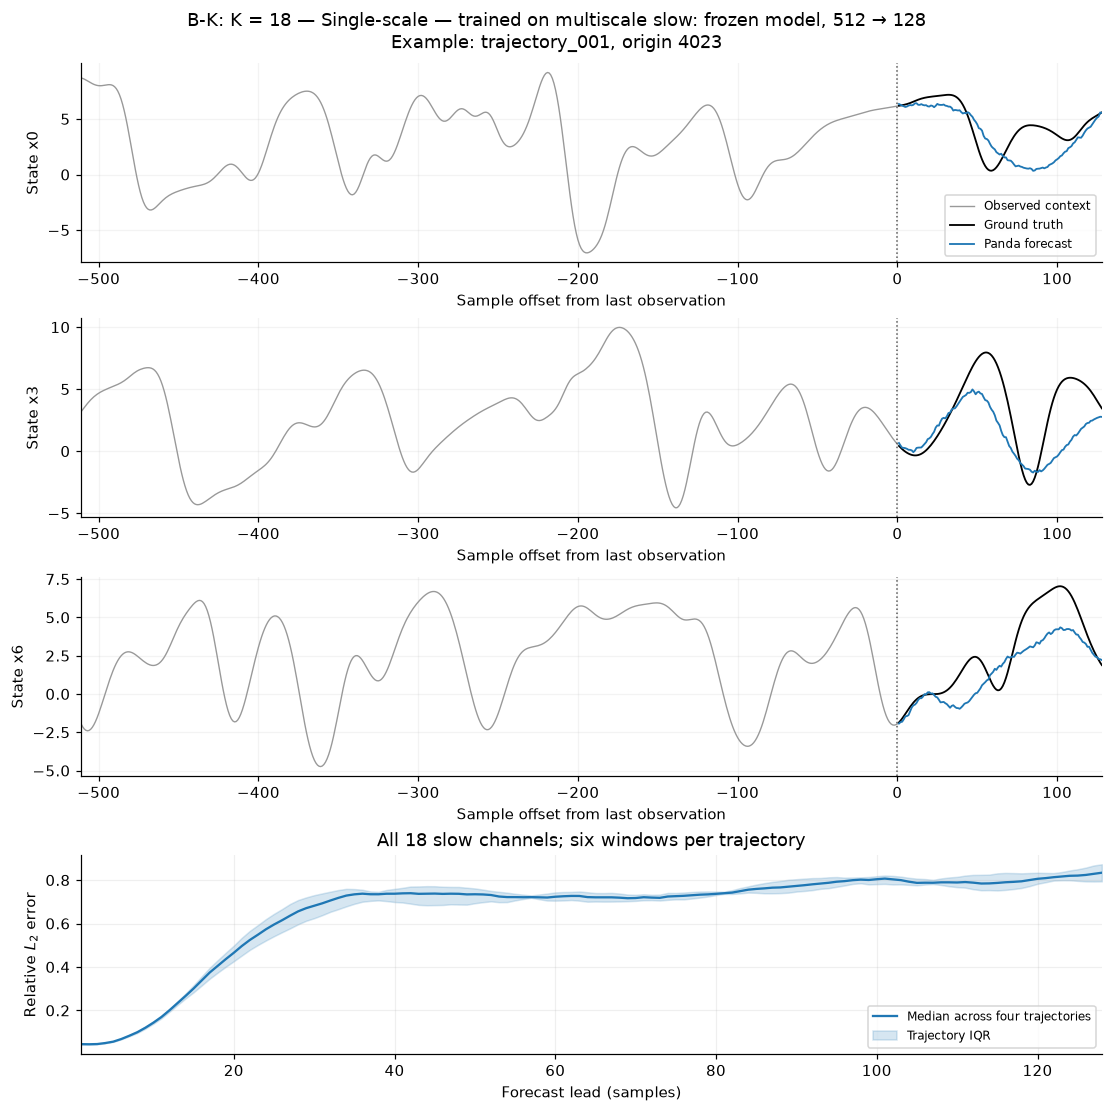

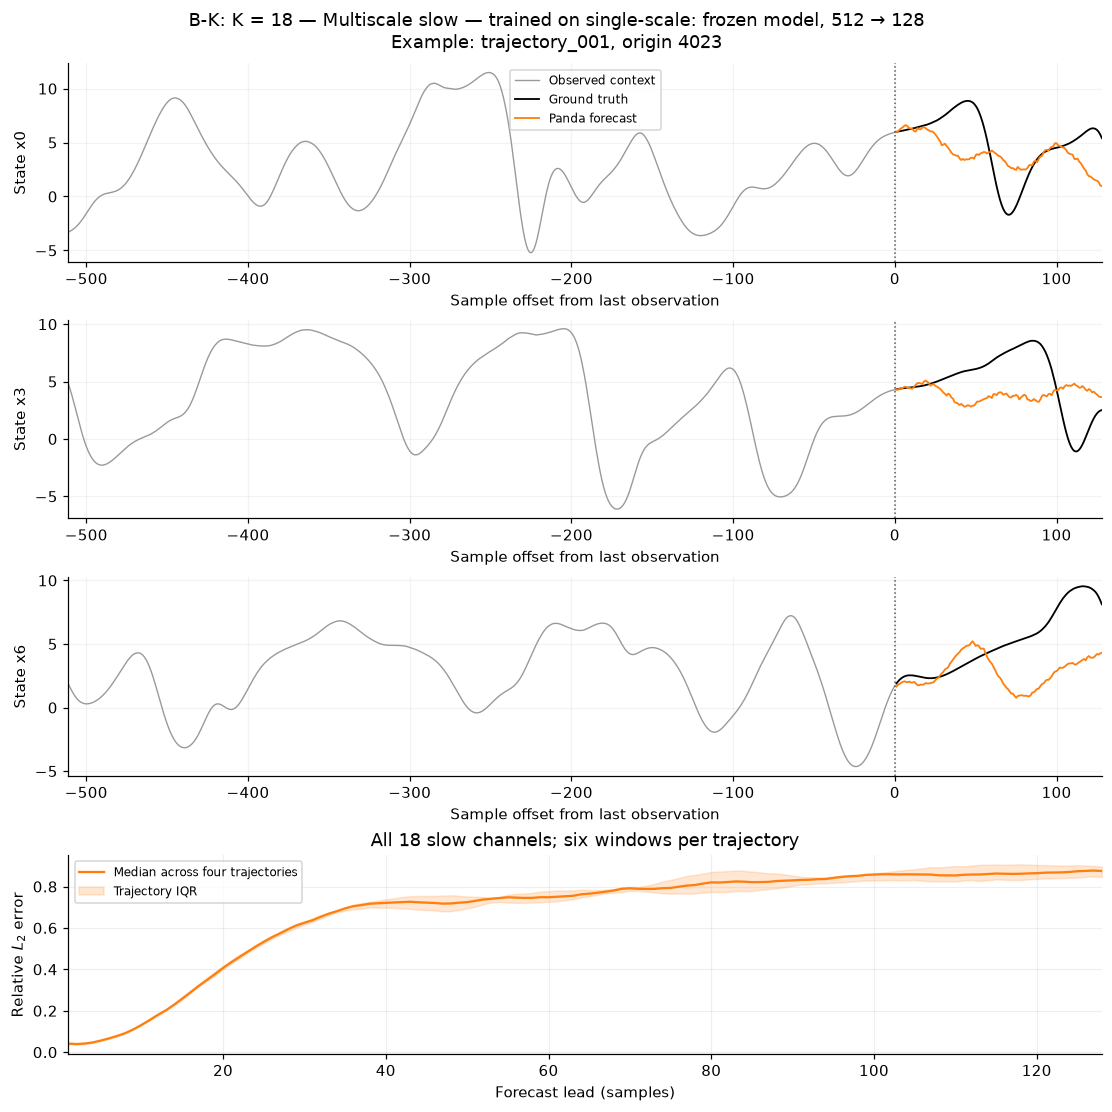

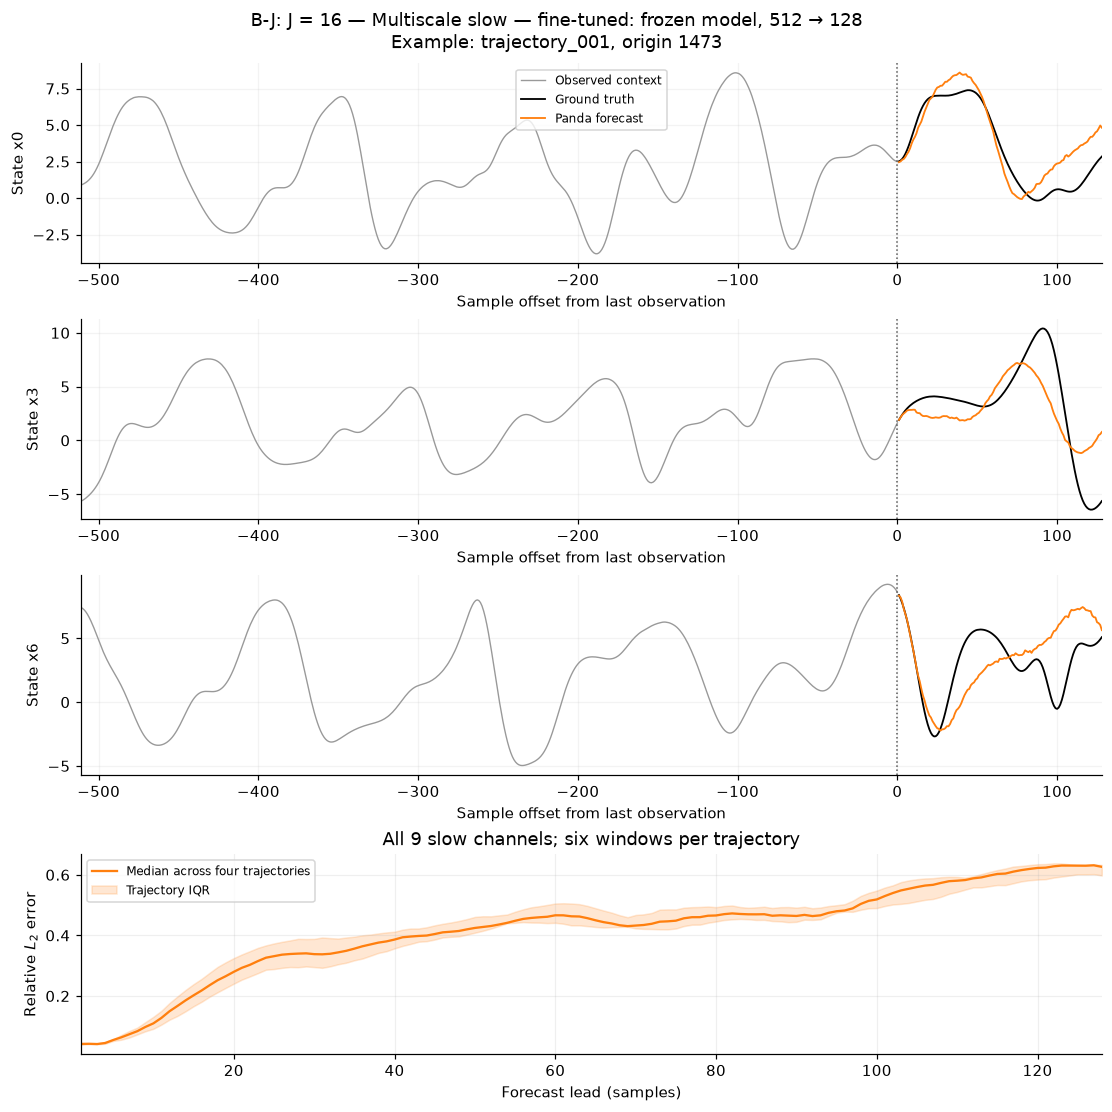

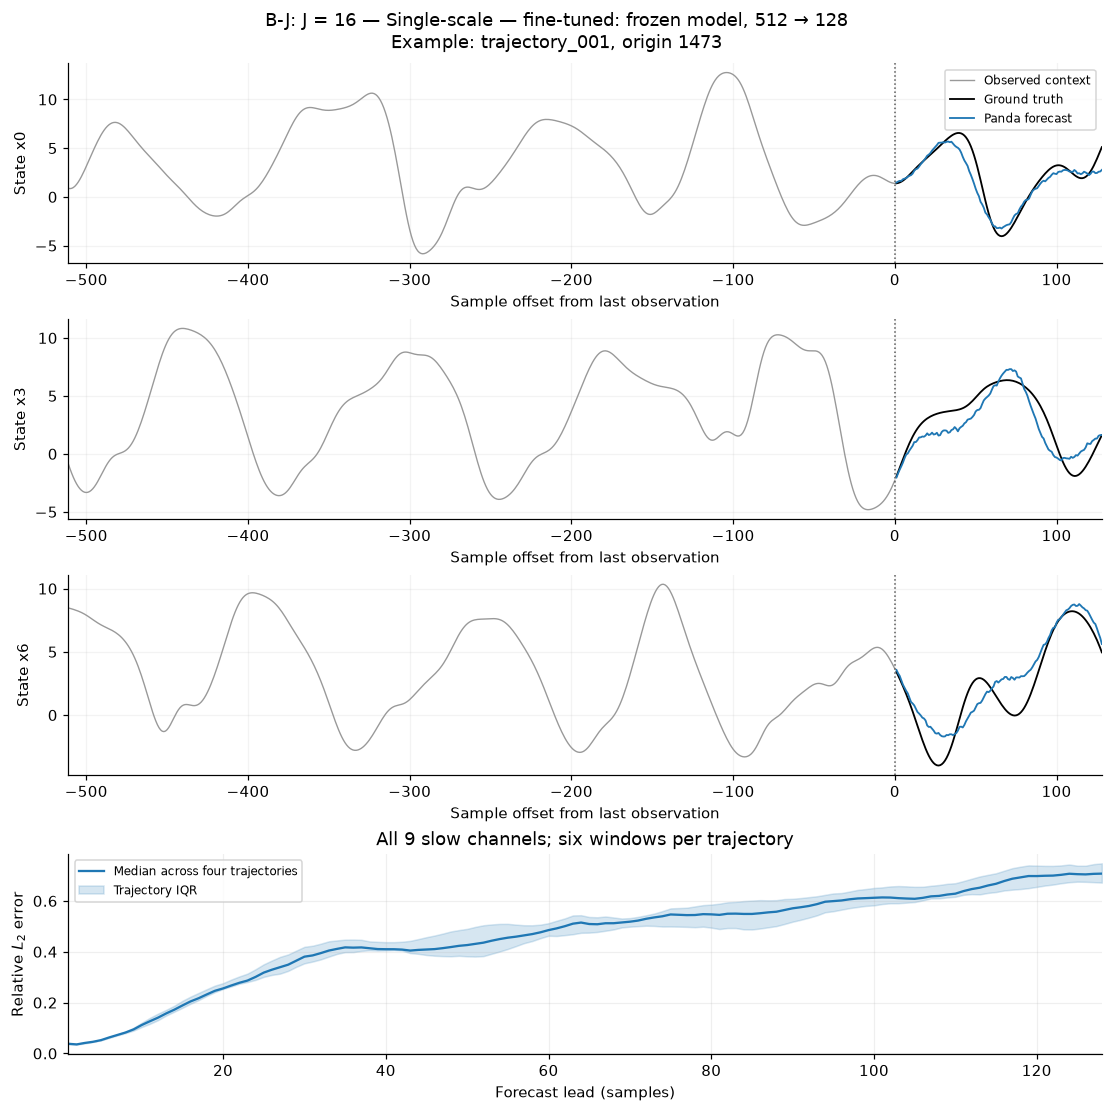

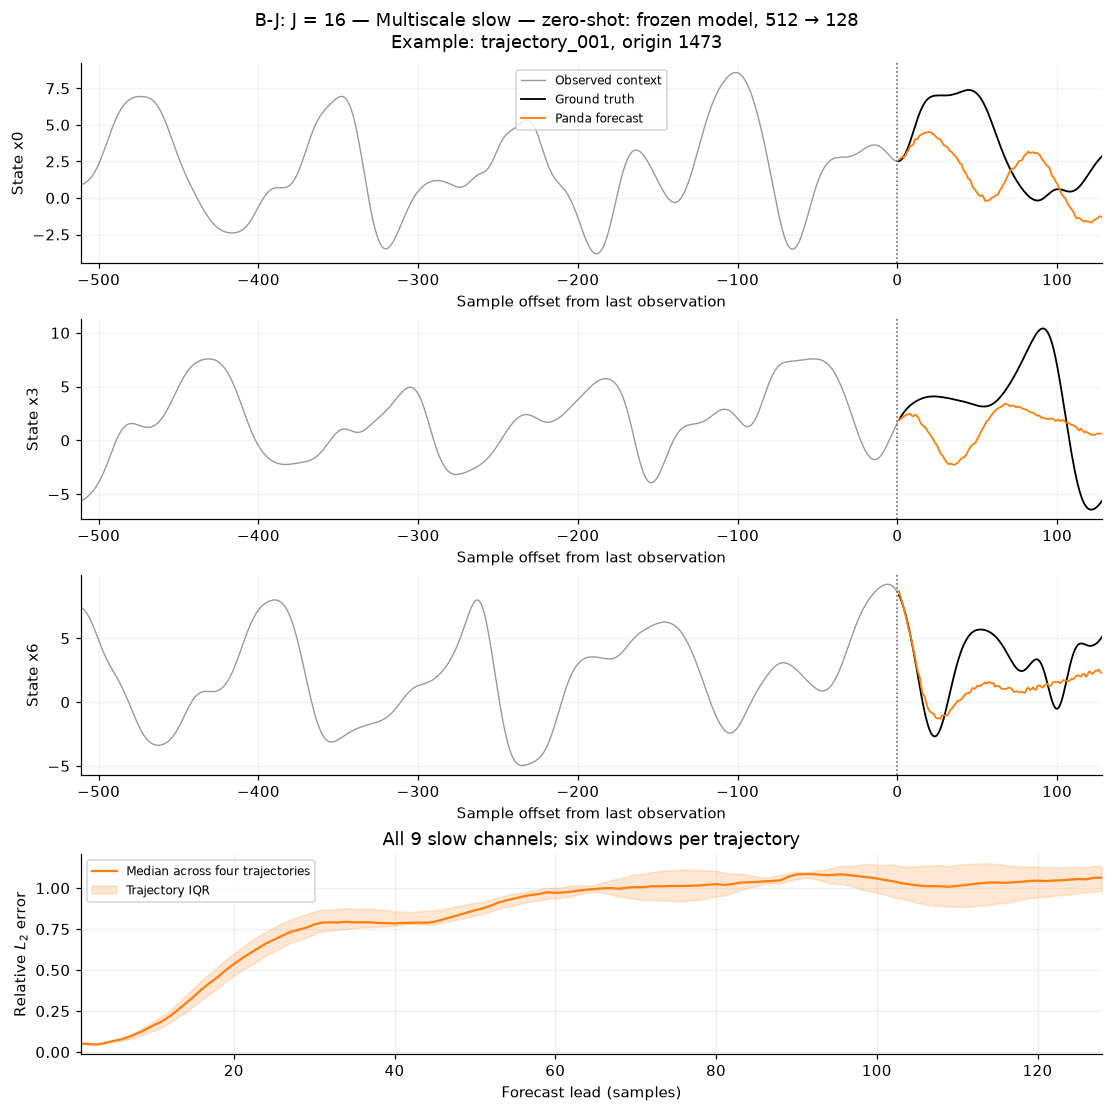

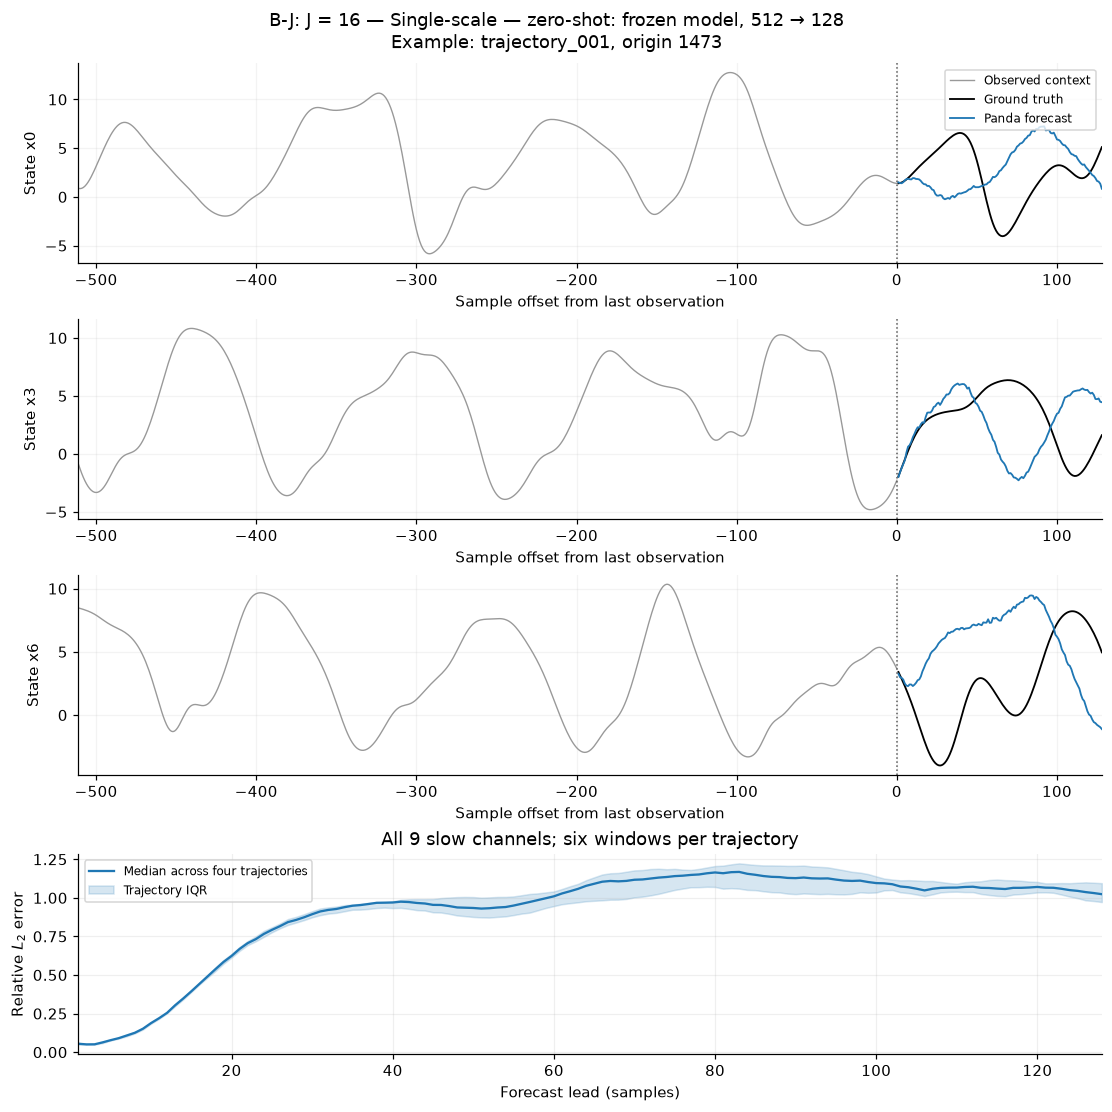

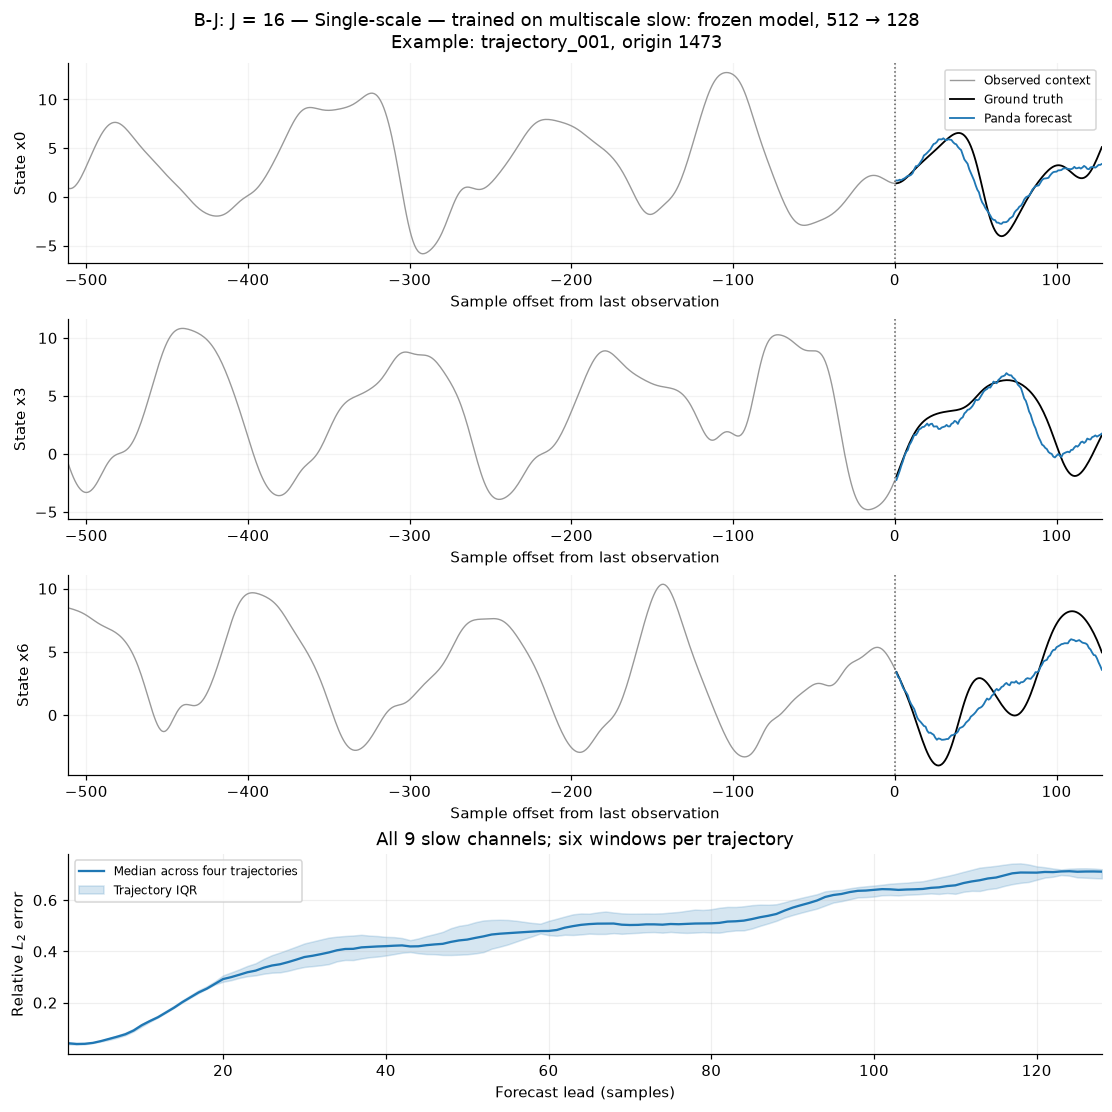

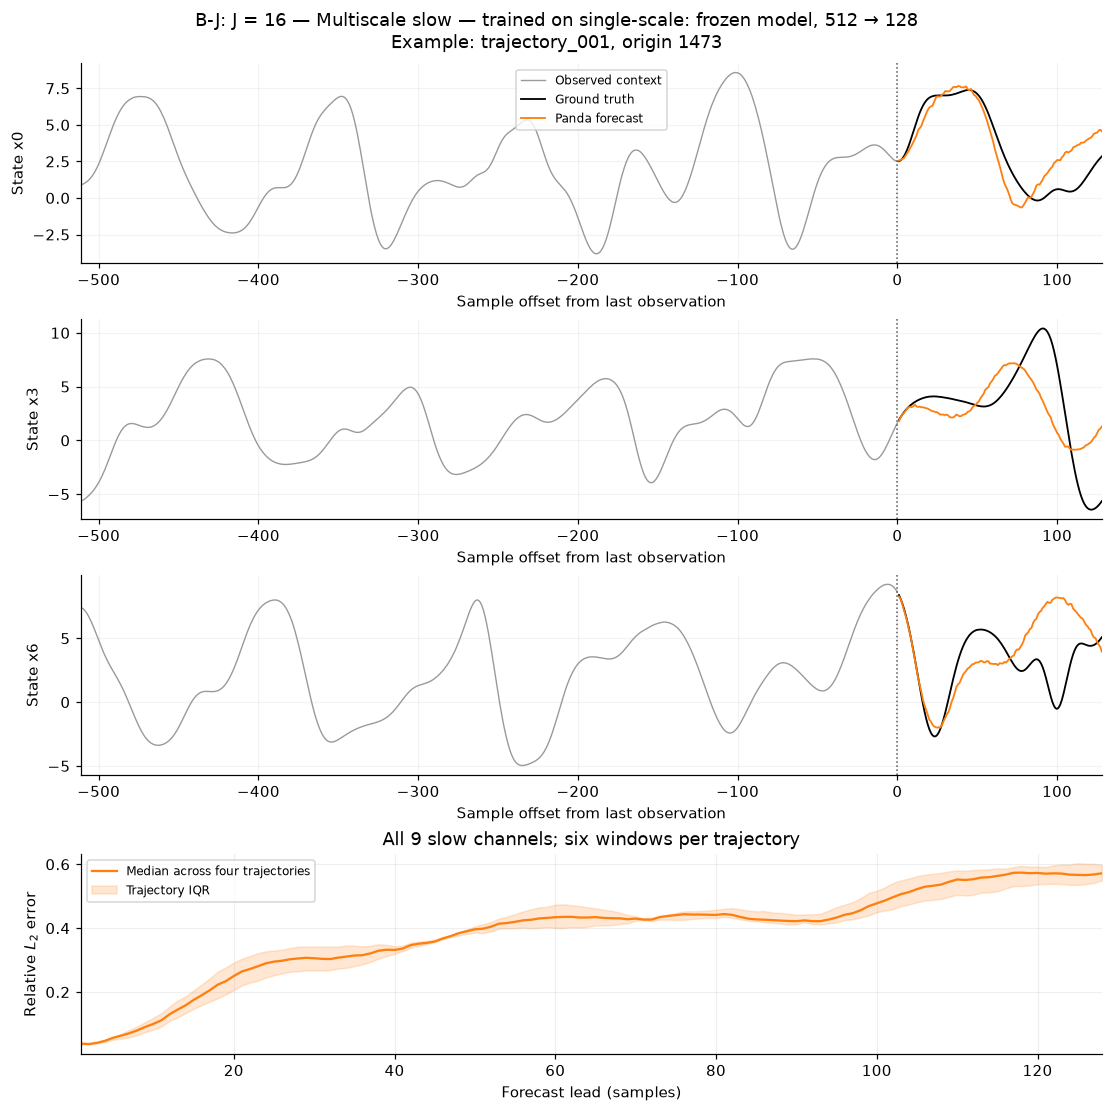

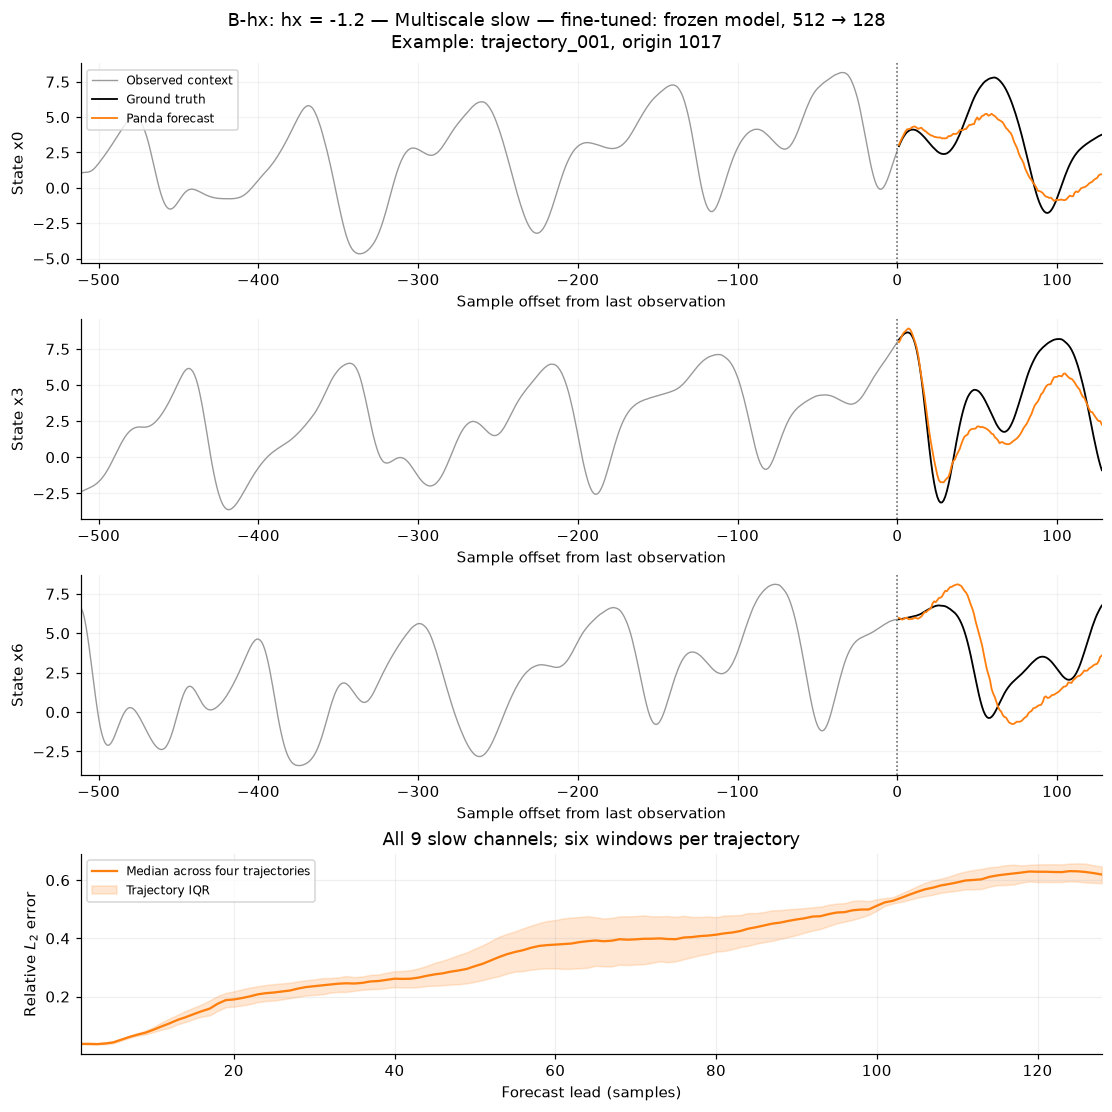

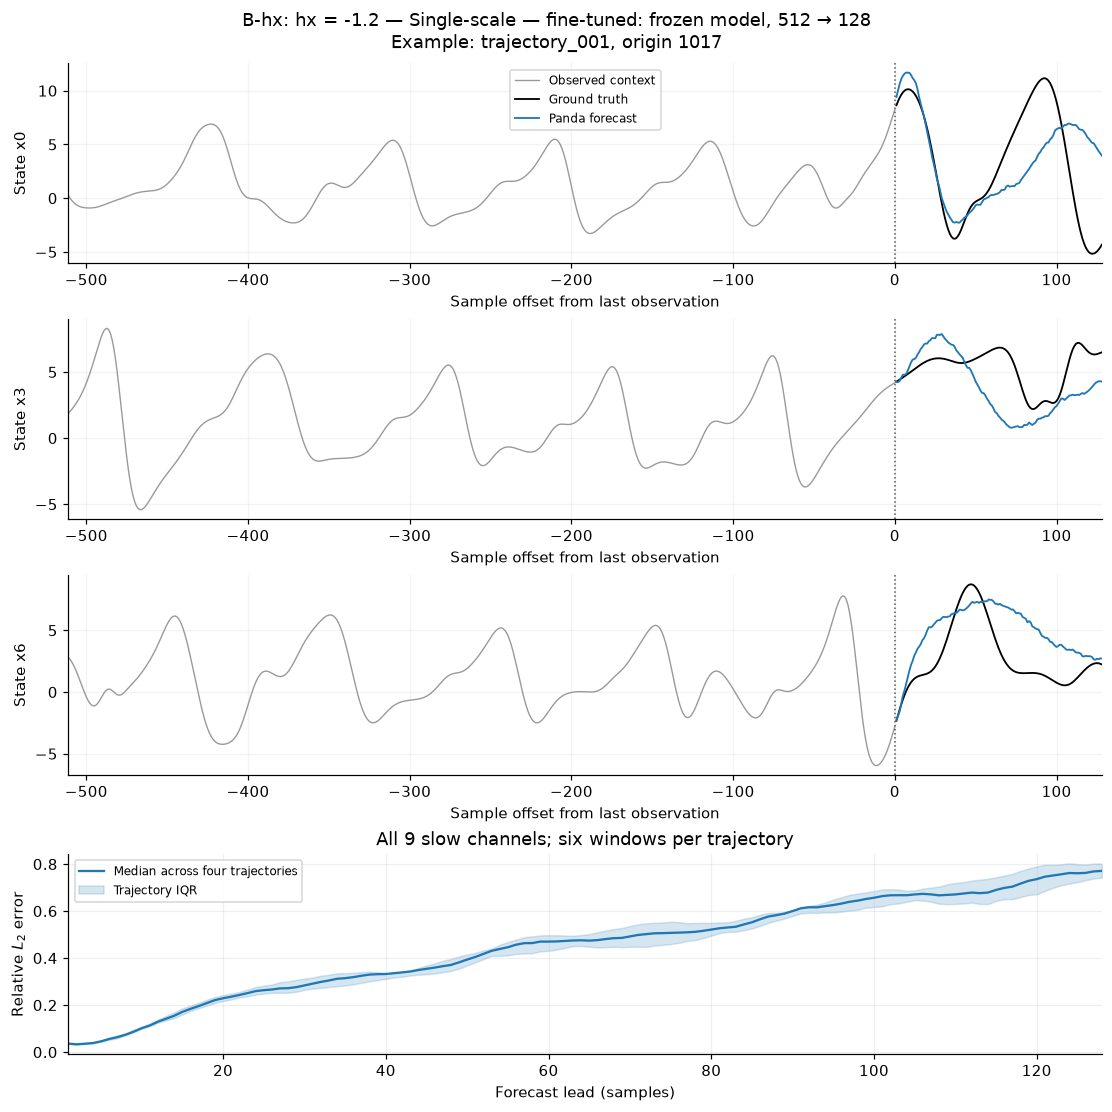

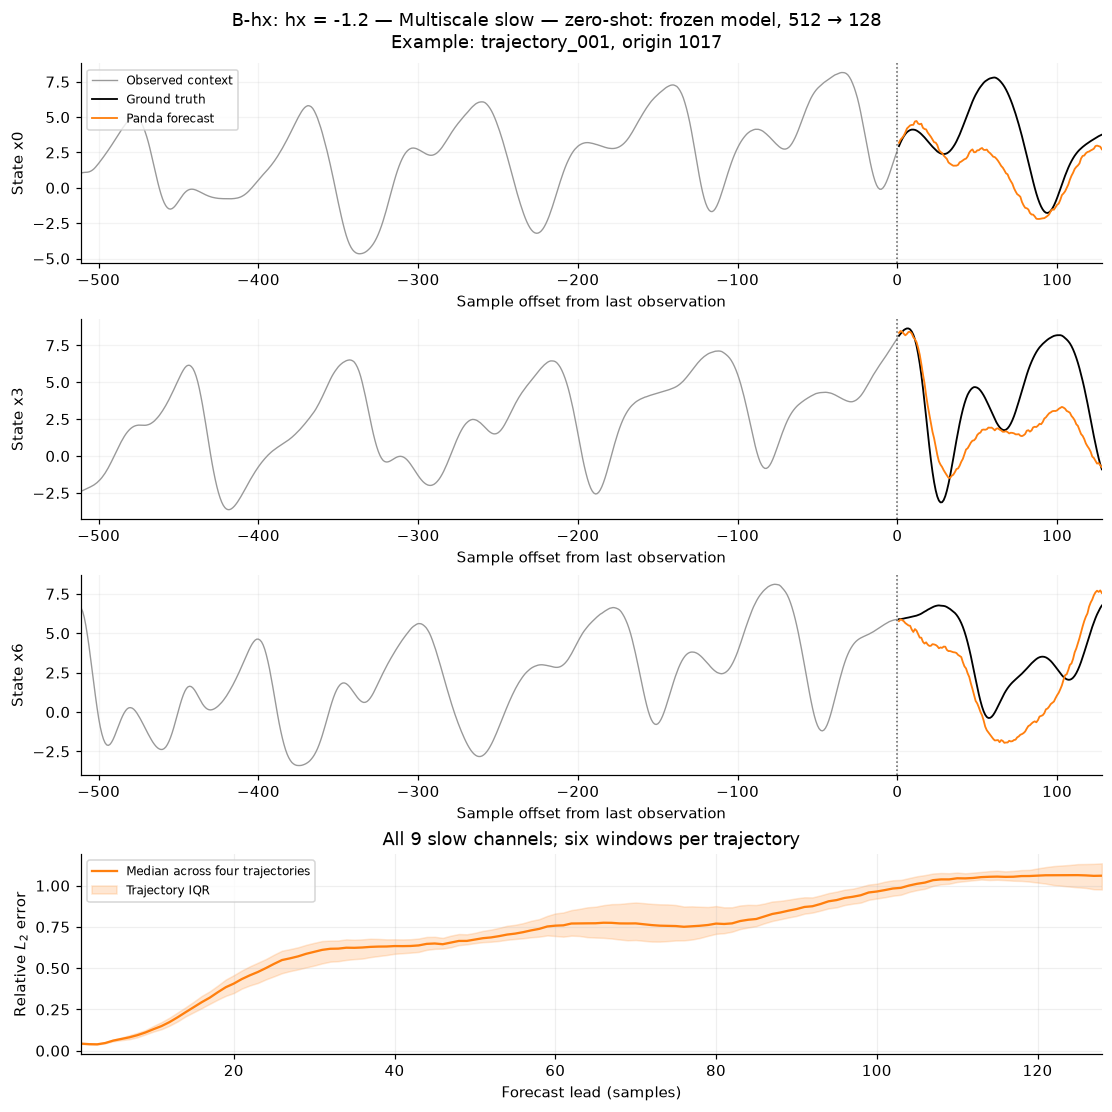

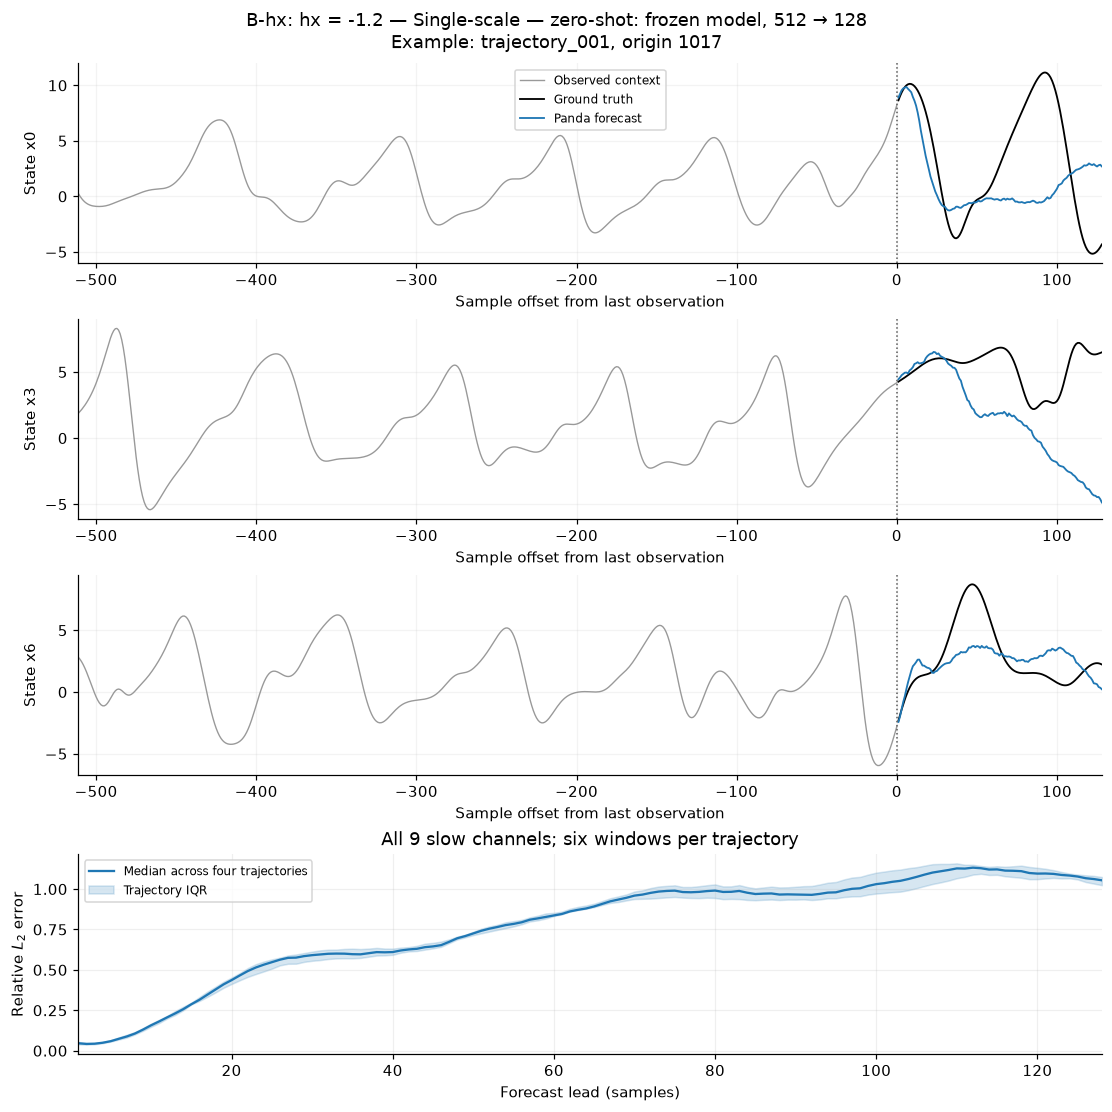

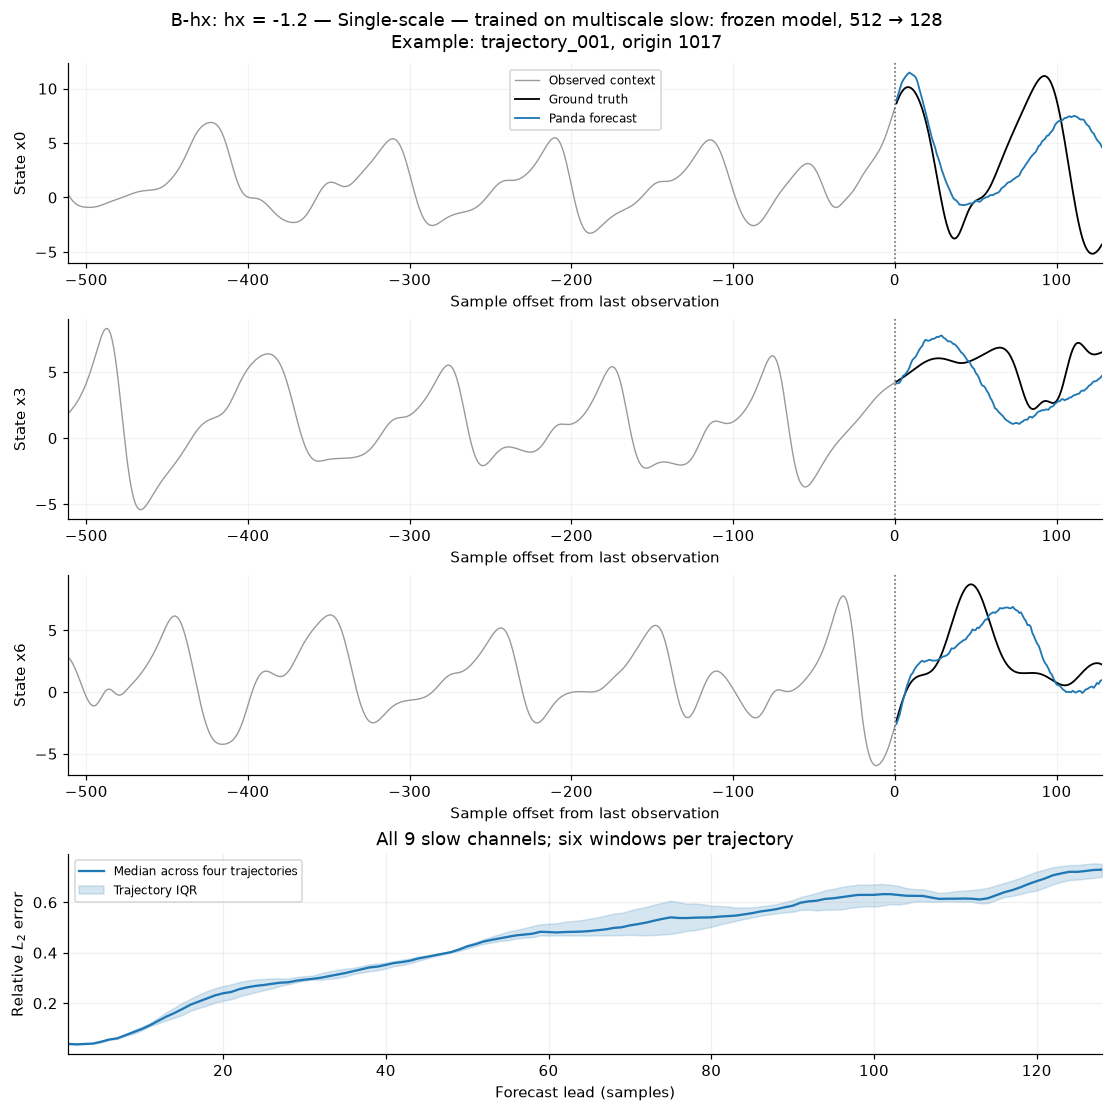

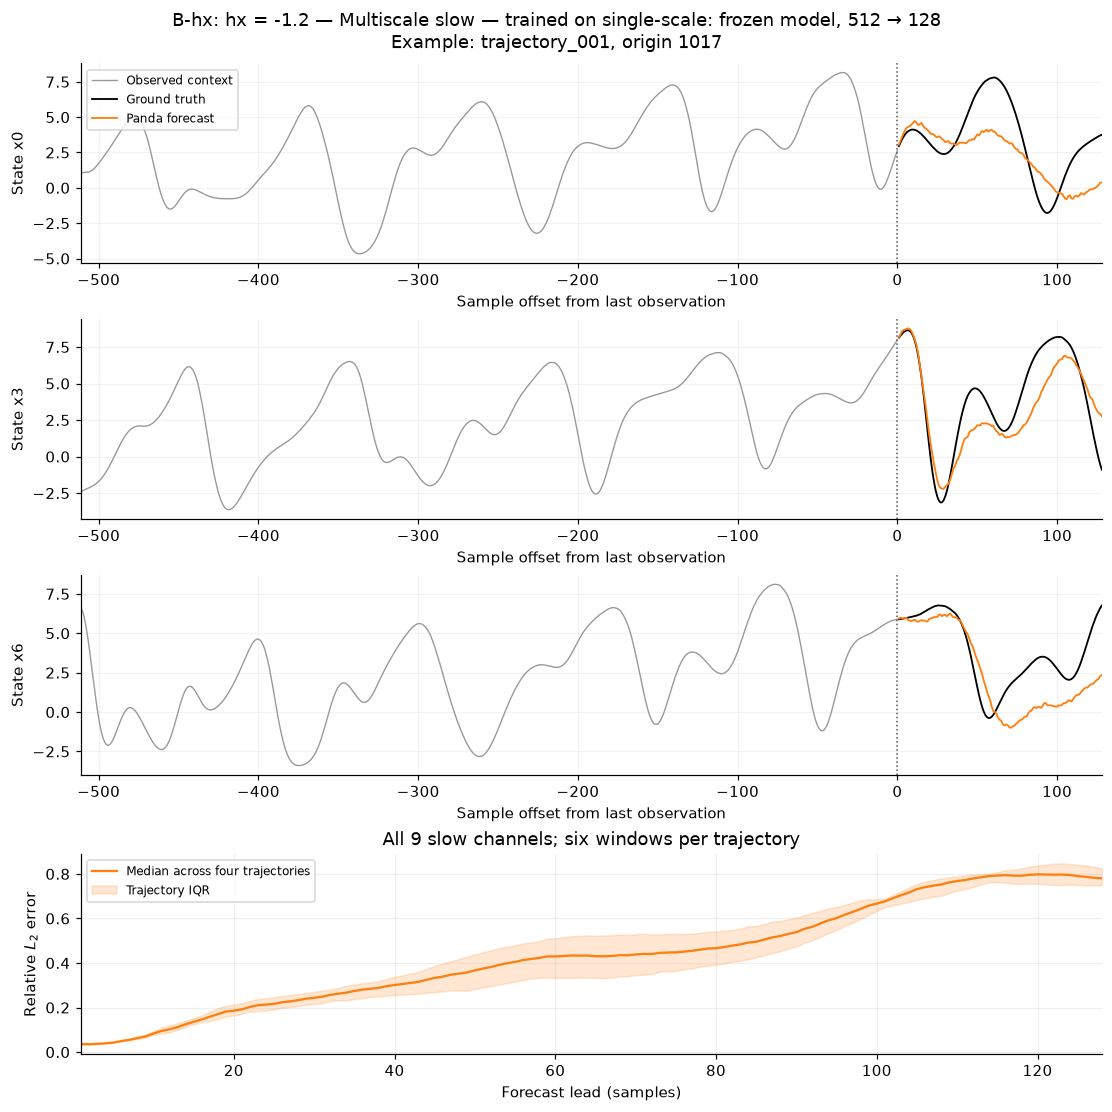

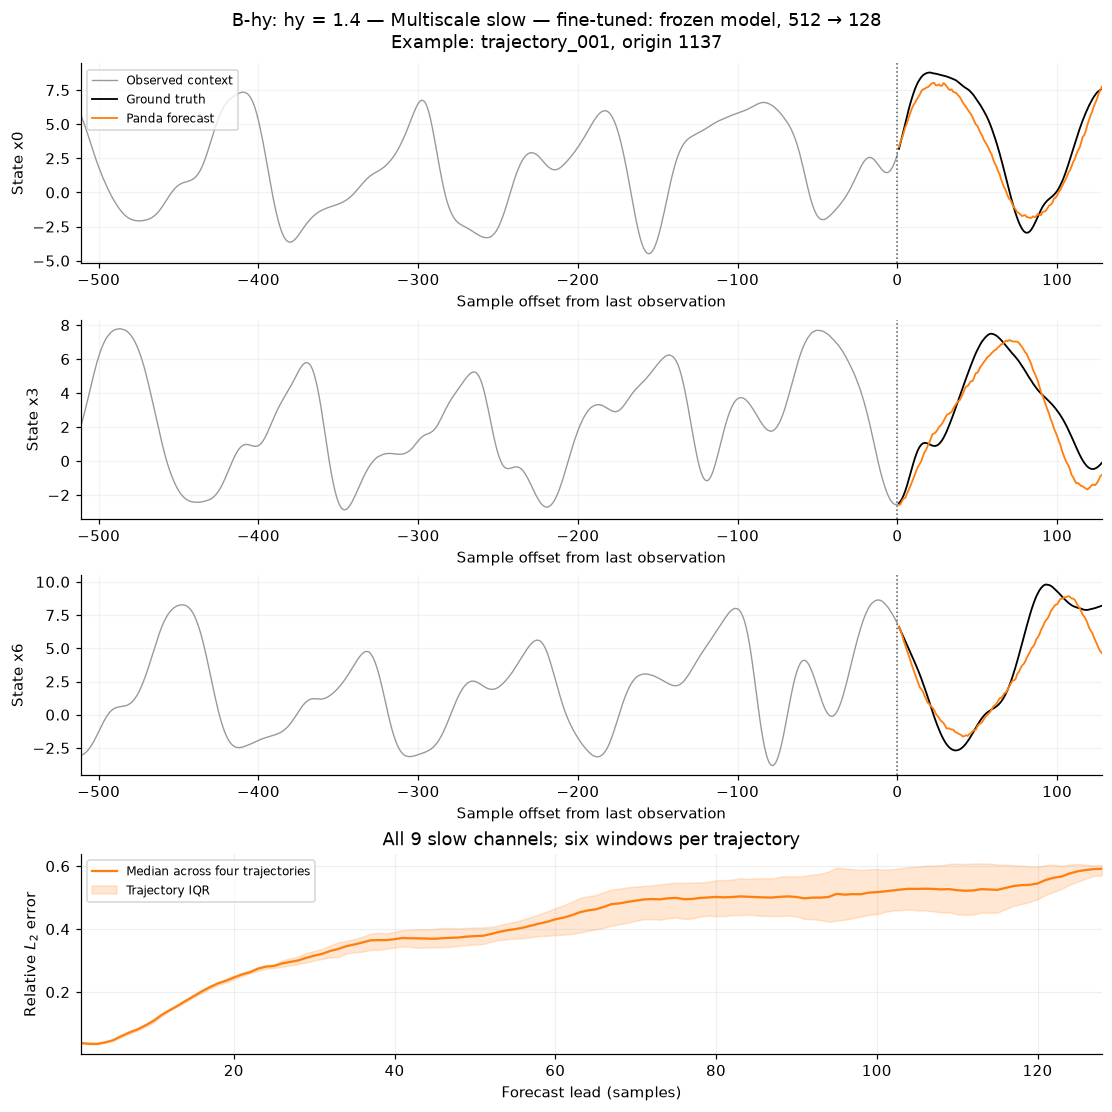

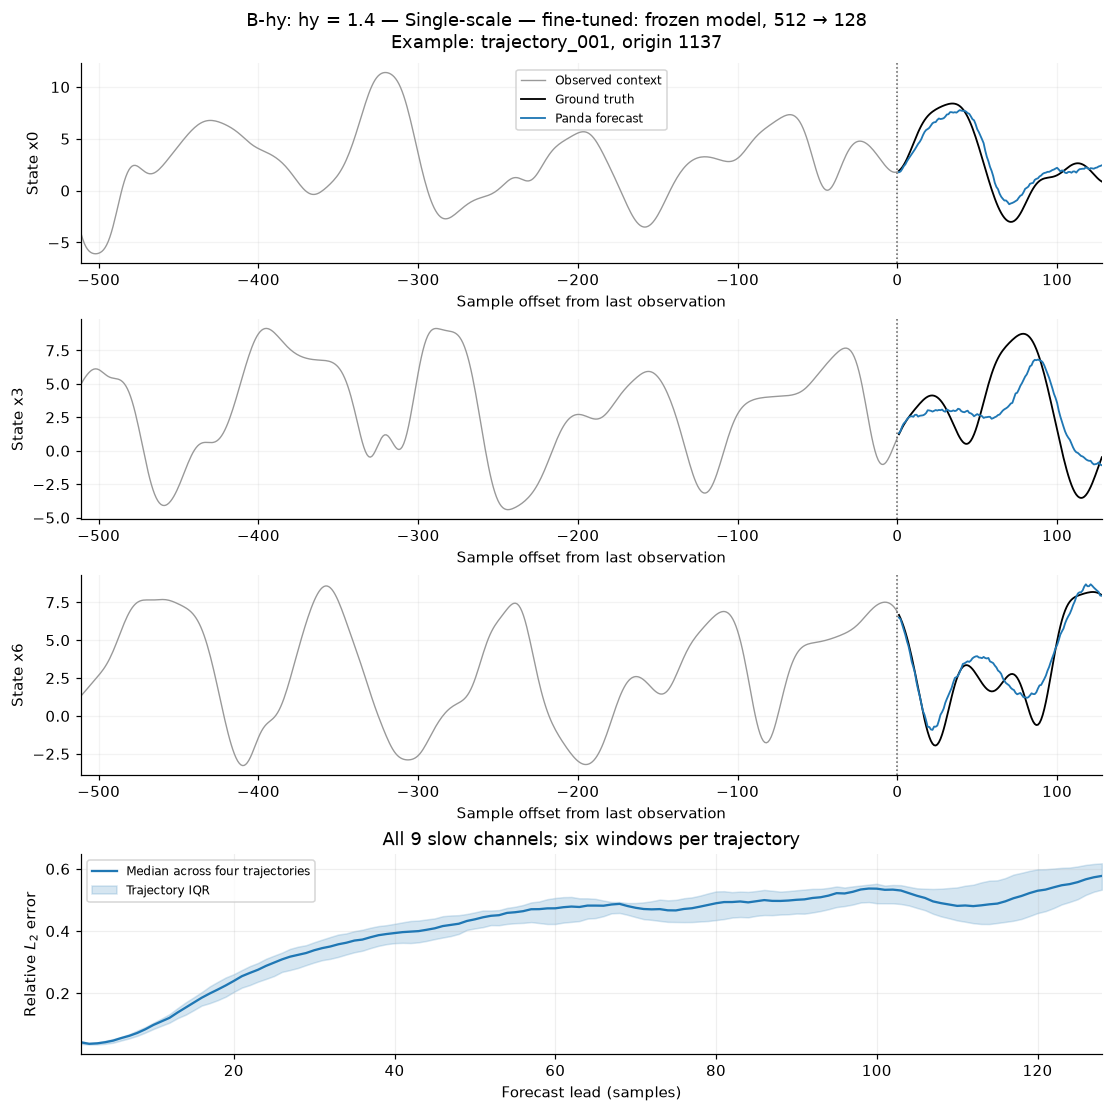

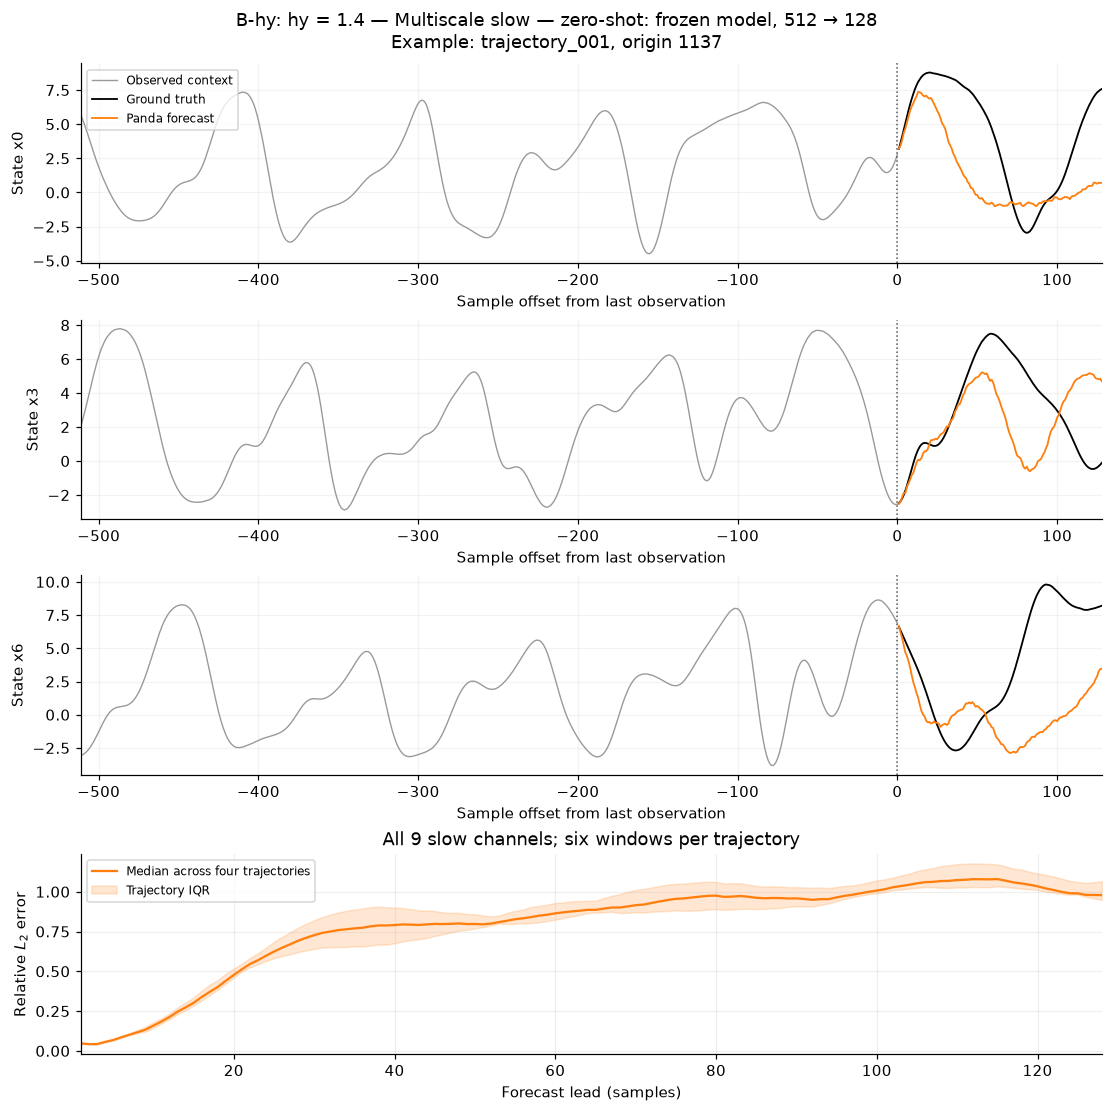

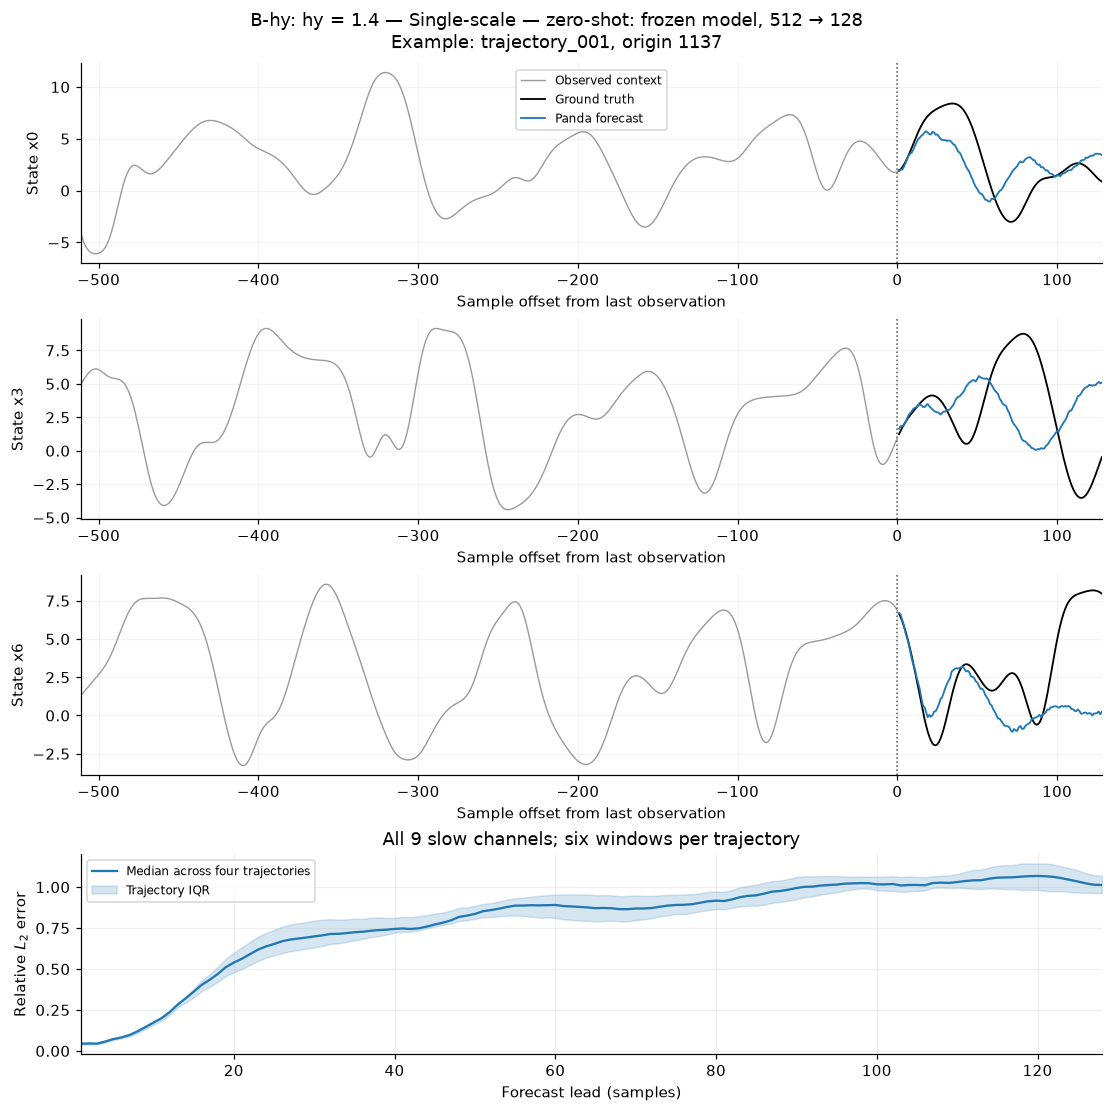

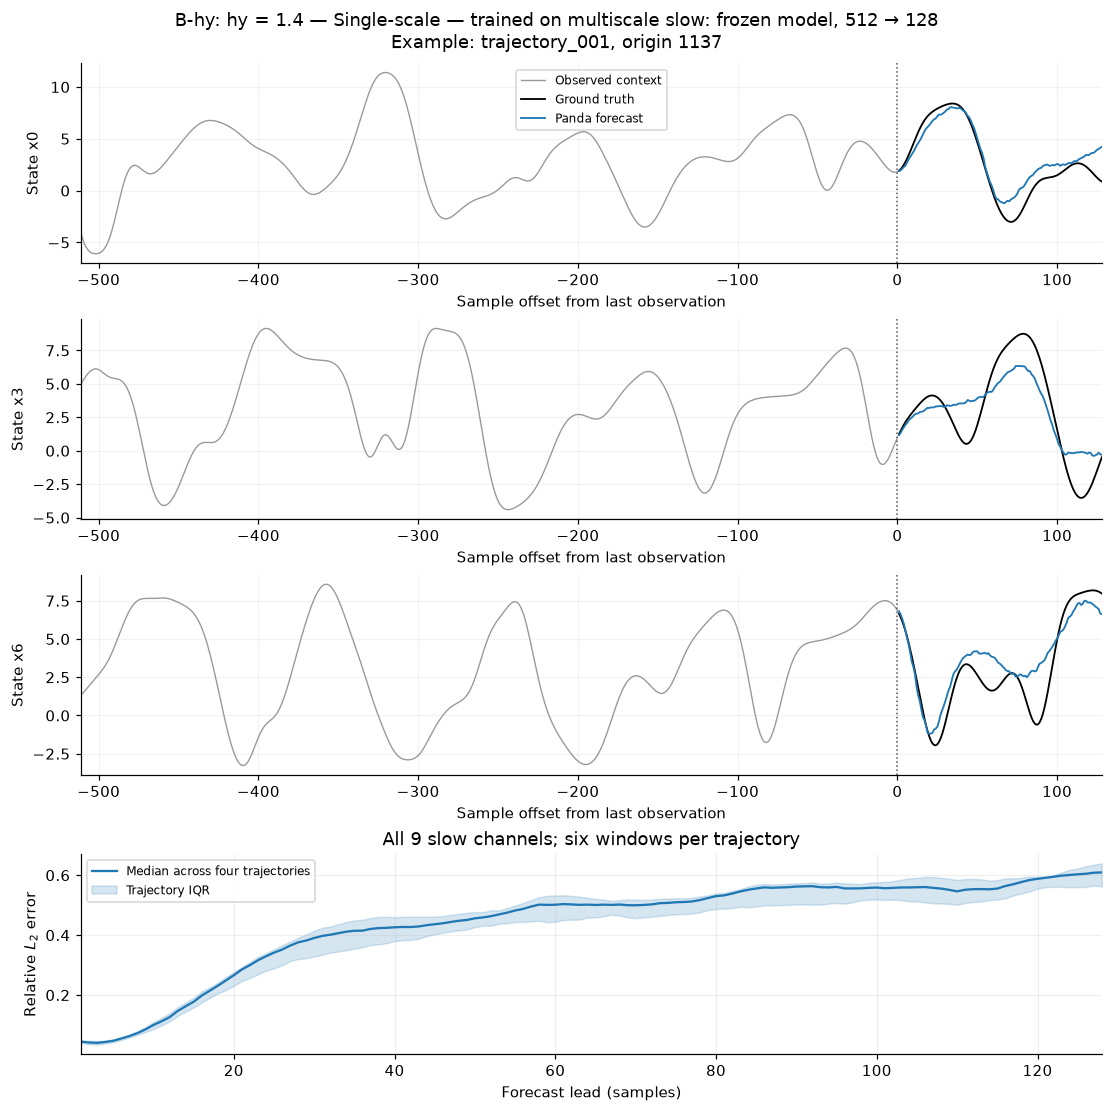

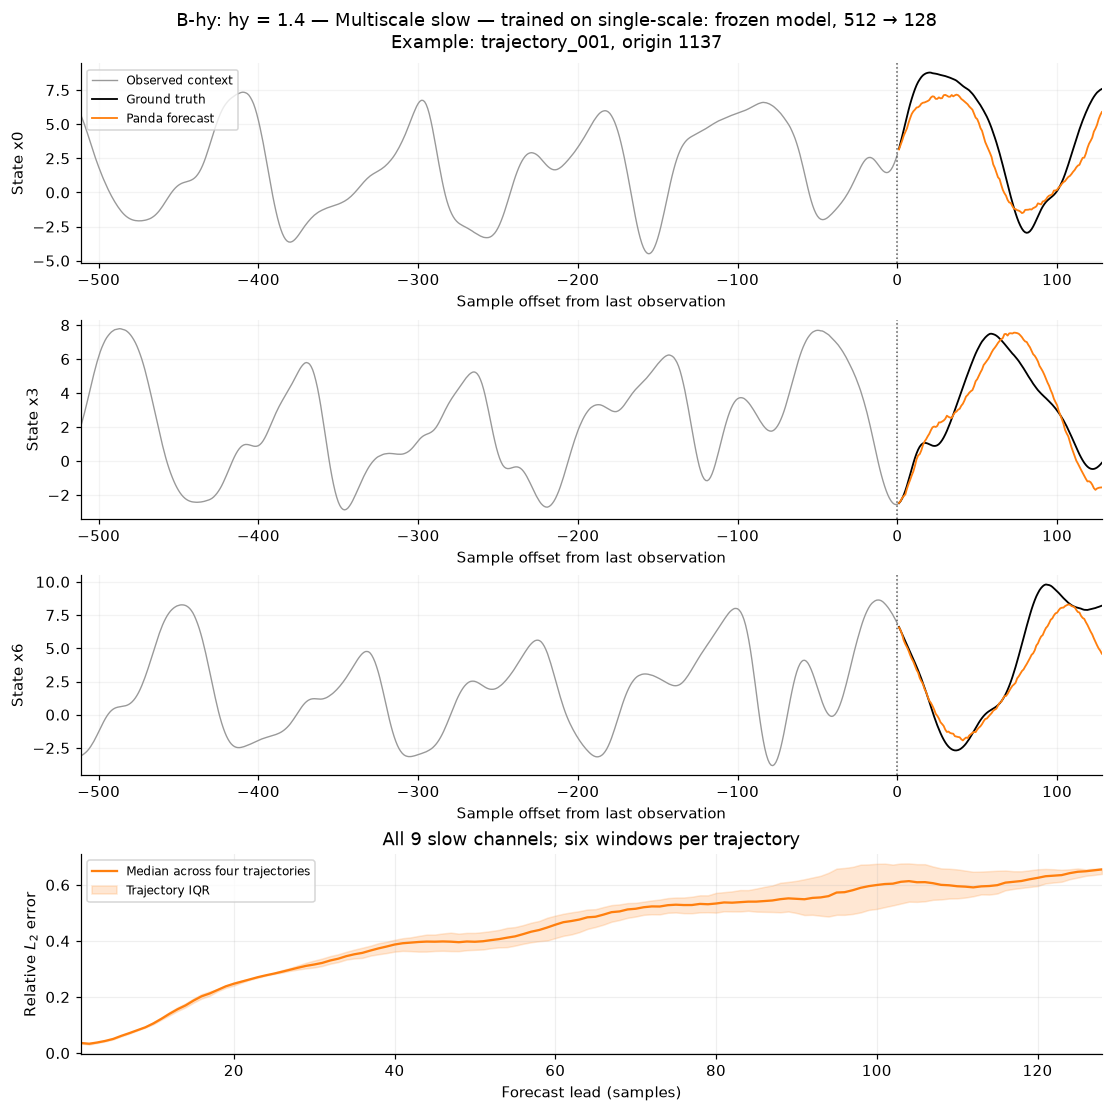

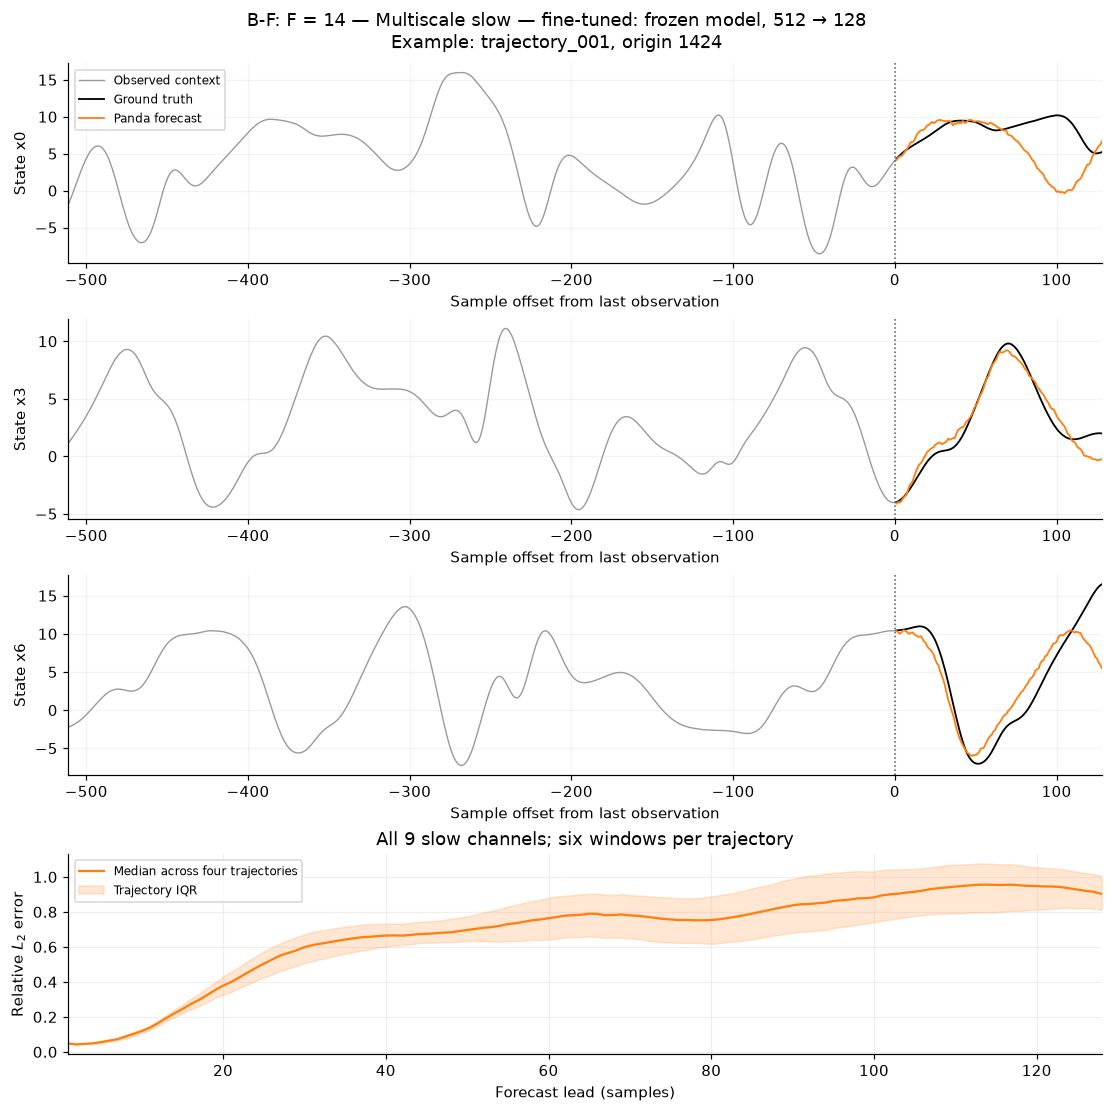

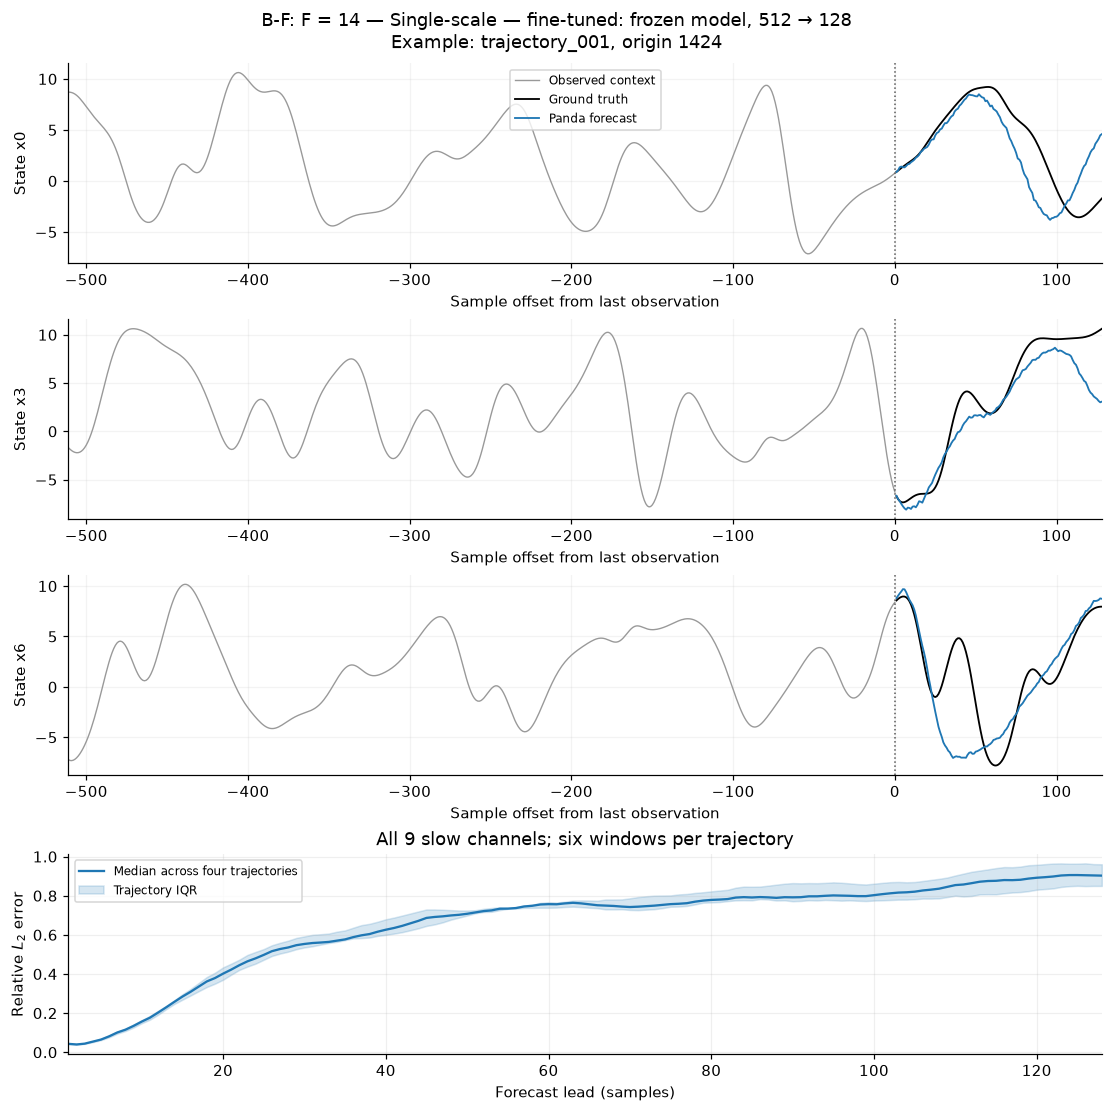

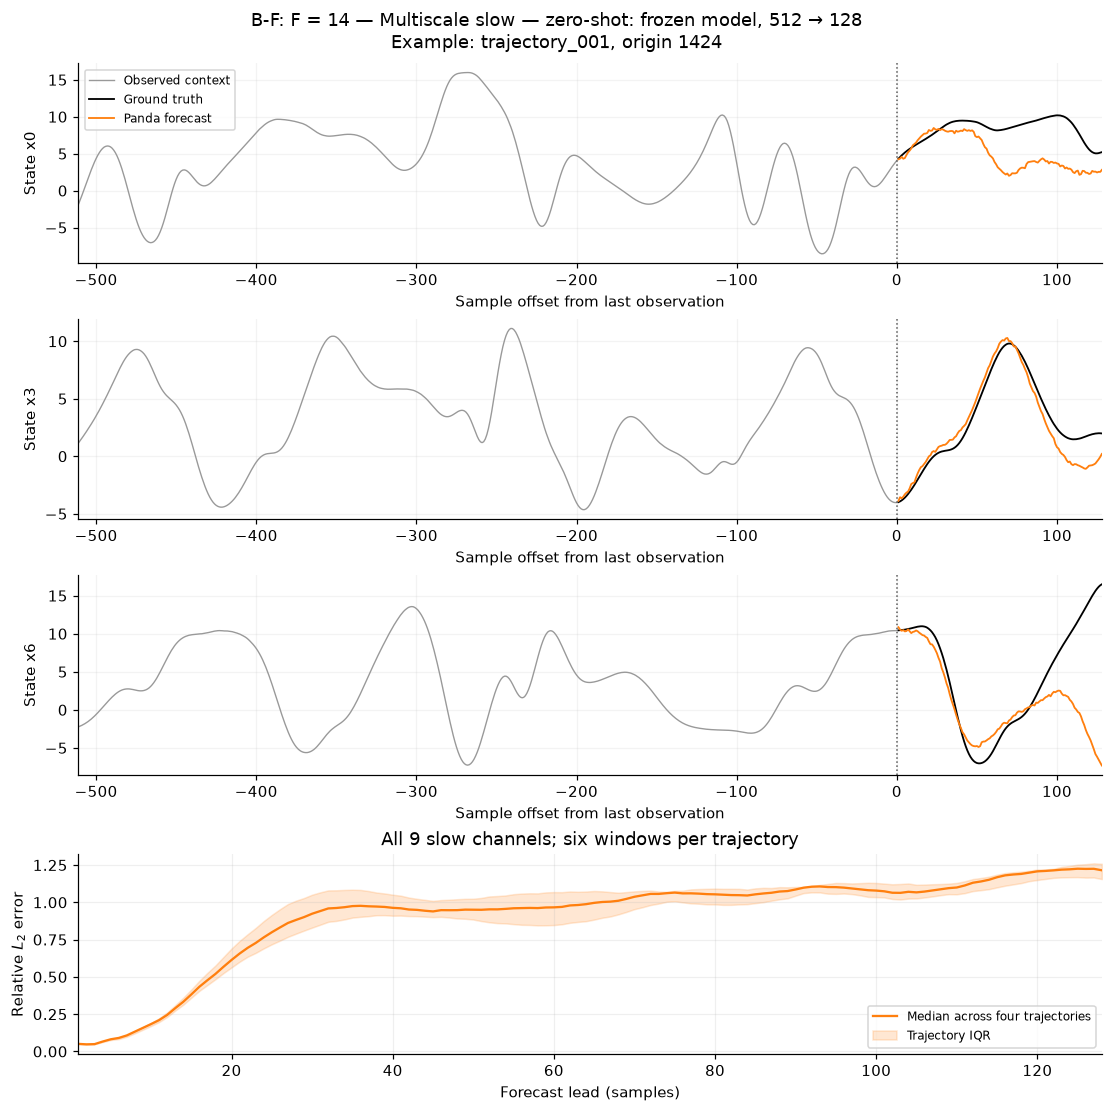

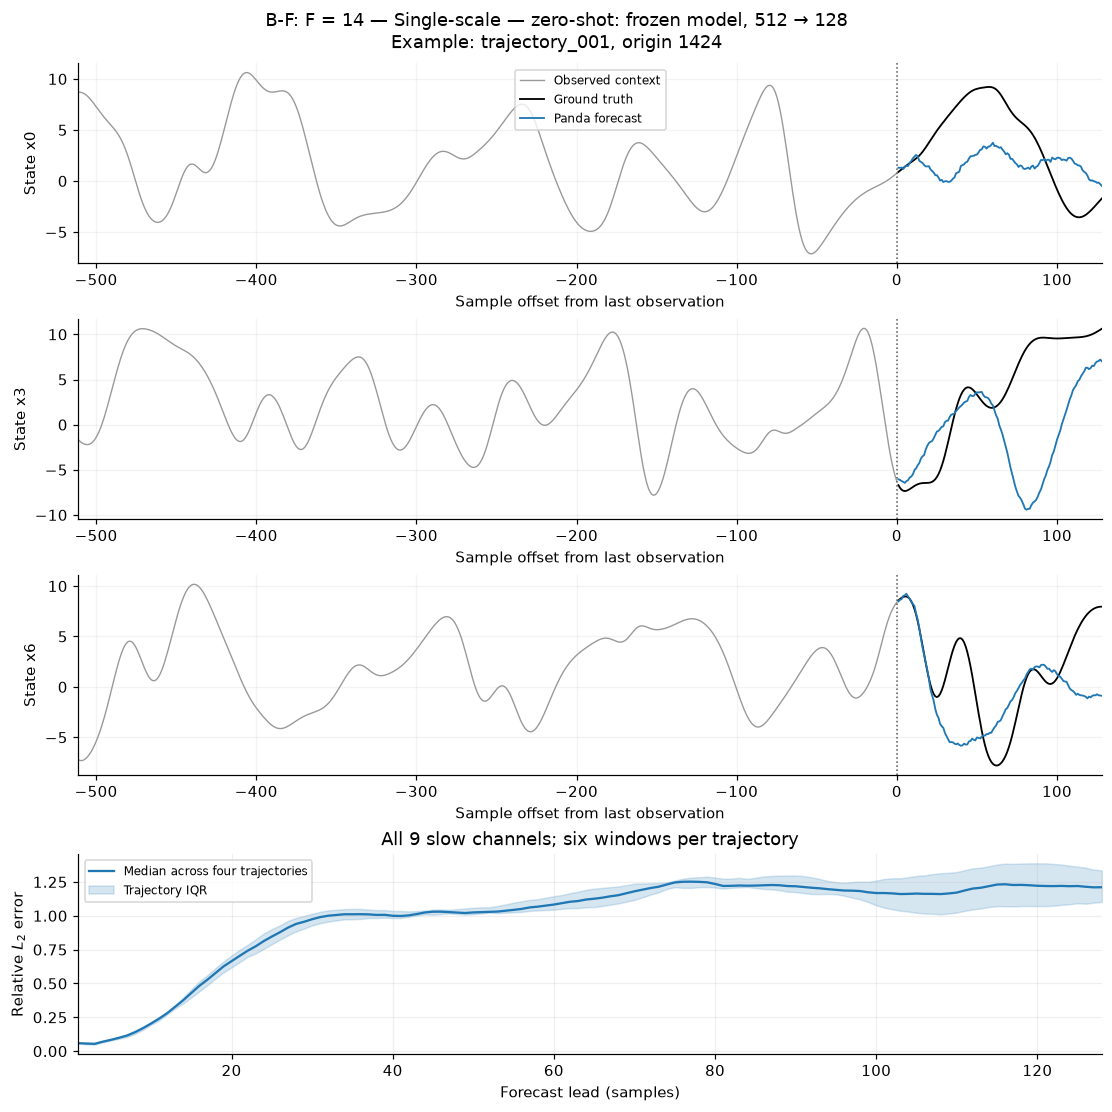

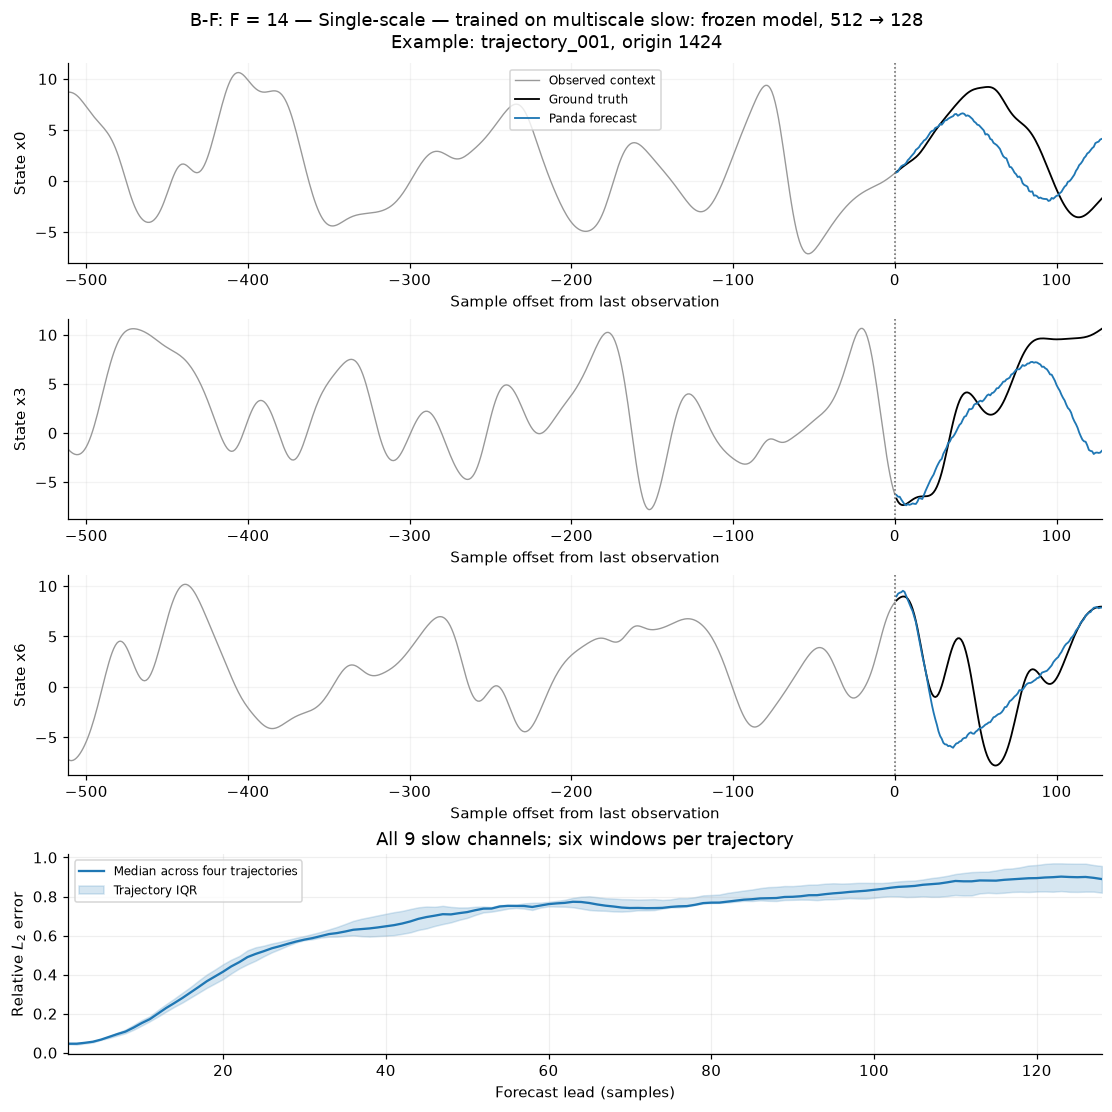

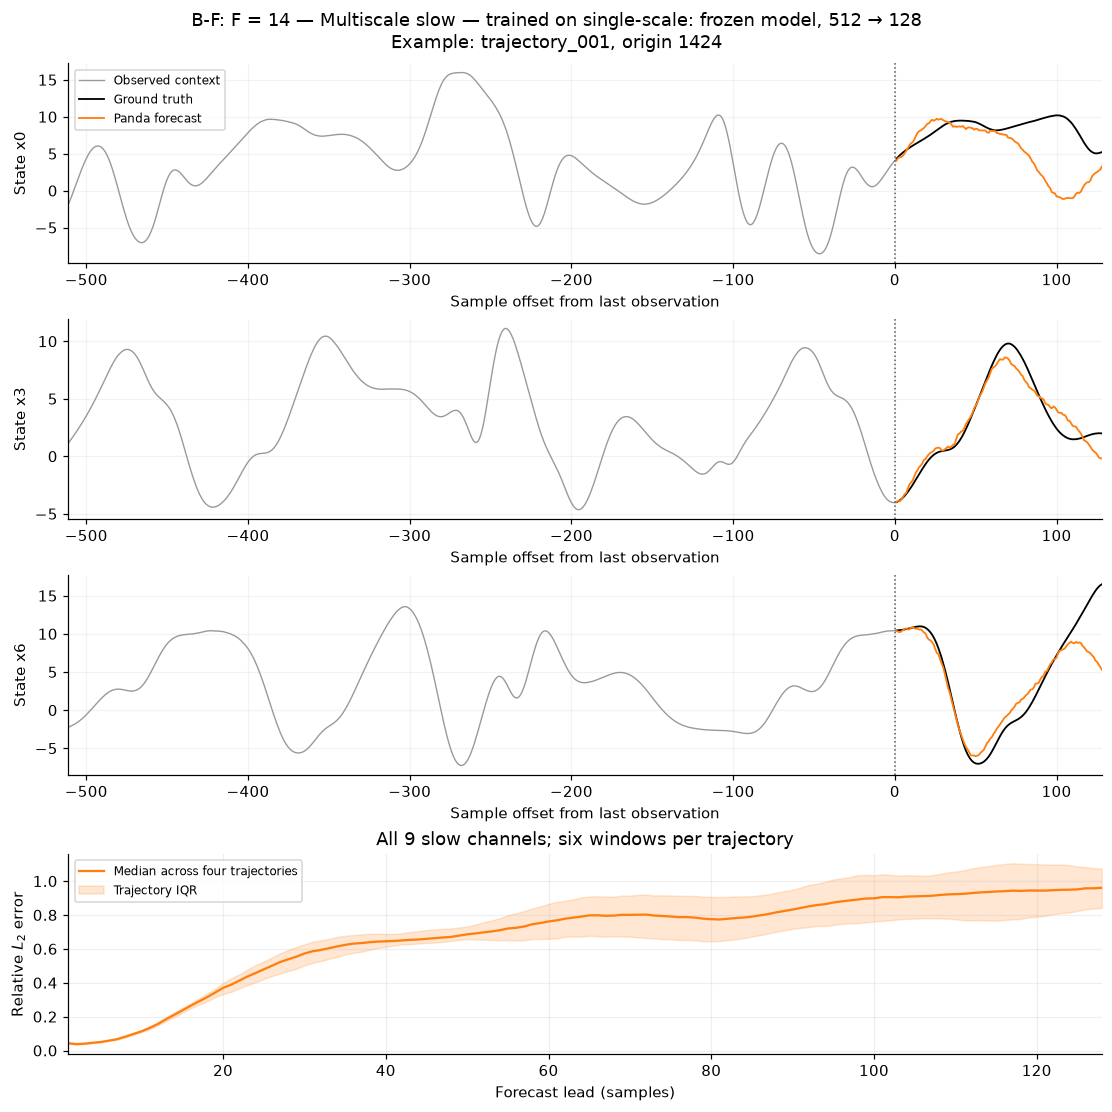

In [16]:
for subset, subset_spec in test_b_specs.items():
    for case, spec in evaluation_cases.items():
        result = test_b_results[subset][case][0]
        context = result["contexts"][0]
        target = result["targets"][0]
        prediction = result["predictions"][0]
        fig, axes = plt.subplots(4, 1, figsize=(10, 10), constrained_layout=True)
        for axis, channel in zip(axes[:3], display_channels):
            axis.plot(context_leads, context[:, channel], color="0.6", linewidth=0.9, label="Observed context")
            axis.plot(lead_times, target[:, channel], color="black", linewidth=1.2, label="Ground truth")
            axis.plot(lead_times, prediction[:, channel], color=spec["color"], linewidth=1.2, label="Panda forecast")
            axis.axvline(0, color="0.35", linestyle=":", linewidth=1)
            axis.set(
                ylabel=f"State x{channel}", xlim=(context_leads[0], prediction_length),
                xlabel="Sample offset from last observation",
            )
            axis.grid(alpha=0.15)
        axes[0].legend(fontsize=8)
        q25, median, q75 = np.quantile(test_b_error_curves[subset][case], [0.25, 0.5, 0.75], axis=0)
        axes[3].plot(lead_times, median, color=spec["color"], label="Median across four trajectories")
        axes[3].fill_between(lead_times, q25, q75, color=spec["color"], alpha=0.18, label="Trajectory IQR")
        axes[3].set(
            xlabel="Forecast lead (samples)", ylabel=r"Relative $L_2$ error",
            xlim=(1, prediction_length), title=f"All {subset_spec['channels']} slow channels; six windows per trajectory",
        )
        axes[3].grid(alpha=0.2)
        axes[3].legend(fontsize=8)
        fig.suptitle(
            f"{subset_spec['label']} — {spec['label']}: frozen model, 512 → 128\n"
            f"Example: {result['trajectory_id']}, origin {result['origins'][0]}"
        )
        plt.show()


### 9.4 Test B summary alongside Test A
Whole-window relative L2 is reported as trajectory-level **mean ± sample standard deviation**. Test A uses 16 trajectories per family; each Test B subset uses four. All cases use six windows per trajectory. These figures summarize only this direct forecast experiment with the existing fine-tuned models and the original checkpoint.


In [17]:
combined_rows = []
for case, spec in evaluation_cases.items():
    metric = "Window relative L2"
    combined_rows.append({
        "Subset": "A: training configuration", "Case": spec["label"], "Trajectories": 16,
        "Window relative L2": f"{summary.loc[spec['label'], (metric, 'mean')]:.4f} ± {summary.loc[spec['label'], (metric, 'std')]:.4f}",
    })
for subset, subset_spec in test_b_specs.items():
    for case, spec in evaluation_cases.items():
        index = (subset_spec["label"], spec["label"])
        combined_rows.append({
            "Subset": subset_spec["label"], "Case": spec["label"], "Trajectories": 4,
            "Window relative L2": test_b_report.loc[index, "Window relative L2"],
        })
display(pd.DataFrame(combined_rows).set_index(["Subset", "Case"]))
print("Completed all five Test B subsets: 720 Test B direct forecasts across six cases; no retraining.")
display(test_b_metrics.set_index(["Subset", "Case", "Trajectory"]).round(4))


Completed all five Test B subsets: 720 Test B direct forecasts across six cases; no retraining.


Trajectories Window relative L2
Subset                    Case                                                                      
A: training configuration Multiscale slow — fine-tuned                         16    0.4516 ± 0.0463
                          Single-scale — fine-tuned                            16    0.4579 ± 0.0750
                          Multiscale slow — zero-shot                          16    0.9082 ± 0.0503
                          Single-scale — zero-shot                             16    0.9263 ± 0.0671
                          Single-scale — trained on multiscale slow            16    0.4731 ± 0.0624
                          Multiscale slow — trained on single-scale            16    0.4777 ± 0.0541
B-K: K = 18               Multiscale slow — fine-tuned                          4    0.7083 ± 0.0352
                          Single-scale — fine-tuned                             4    0.7177 ± 0.0308
                          Multiscale slow — zero-shot                           4    1.0187 ± 0.0289
                          Single-scale — zero-shot                              4    0.9835 ± 0.0061
                          Single-scale — trained on multiscale slow             4    0.6946 ± 0.0226
                          Multiscale slow — trained on single-scale             4    0.7180 ± 0.0278
B-J: J = 16               Multiscale slow — fine-tuned                          4    0.4556 ± 0.0477
                          Single-scale — fine-tuned                             4    0.5112 ± 0.0585
                          Multiscale slow — zero-shot                           4    0.9138 ± 0.0496
                          Single-scale — zero-shot                              4    0.9604 ± 0.0644
                          Single-scale — trained on multiscale slow             4    0.5176 ± 0.0570
                          Multiscale slow — trained on single-scale             4    0.4224 ± 0.0335
B-hx: hx = -1.2           Multiscale slow — fine-tuned                          4    0.4115 ± 0.0419
                          Single-scale — fine-tuned                             4    0.4972 ± 0.0376
                          Multiscale slow — zero-shot                           4    0.7845 ± 0.0807
                          Single-scale — zero-shot                              4    0.8422 ± 0.0250
                          Single-scale — trained on multiscale slow             4    0.4979 ± 0.0302
                          Multiscale slow — trained on single-scale             4    0.4932 ± 0.0520
B-hy: hy = 1.4            Multiscale slow — fine-tuned                          4    0.4364 ± 0.0693
                          Single-scale — fine-tuned                             4    0.4310 ± 0.0609
                          Multiscale slow — zero-shot                           4    0.8781 ± 0.0982
                          Single-scale — zero-shot                              4    0.8606 ± 0.0942
                          Single-scale — trained on multiscale slow             4    0.4544 ± 0.0722
                          Multiscale slow — trained on single-scale             4    0.4760 ± 0.0614
B-F: F = 14               Multiscale slow — fine-tuned                          4    0.7325 ± 0.1412
                          Single-scale — fine-tuned                             4    0.7178 ± 0.0538
                          Multiscale slow — zero-shot                           4    0.9689 ± 0.1106
                          Single-scale — zero-shot                              4    1.0605 ± 0.0728
                          Single-scale — trained on multiscale slow             4    0.7180 ± 0.0426
                          Multiscale slow — trained on single-scale             4    0.7395 ± 0.1349

Window relative L2  ...  Lead 128 relative L2
Subset      Case                                      Trajectory                          ...                      
B-K: K = 18 Multiscale slow — fine-tuned              trajectory_001              0.7413  ...                0.8612
                                                      trajectory_002              0.7308  ...                0.8760
                                                      trajectory_003              0.6635  ...                0.7651
                                                      trajectory_004              0.6975  ...                0.8340
            Single-scale — fine-tuned                 trajectory_001              0.7305  ...                0.8125
...                                                                                  ...  ...                   ...
B-F: F = 14 Single-scale — trained on multiscale slow trajectory_004              0.6641  ...                0.7806
            Multiscale slow — trained on single-scale trajectory_001              0.5926  ...                0.8549
                                                      trajectory_002              0.8355  ...                1.0916
                                                      trajectory_003              0.6589  ...                0.8070
                                                      trajectory_004              0.8710  ...                1.0664

[120 rows x 3 columns]